# Proyecto 2 — Magnetohidrodinámica: el *MHD Rotor* con PLUTO y con un solver propio en Python

**Curso:** Astrofísica Computacional 2026-II  **Autor:** _(completar)_  **Fecha:** octubre de 2026

**Problema elegido:** `PLUTO/Test_Problems/MHD/Rotor`, configuración #01 (geometría cartesiana, 2D, $\nabla\cdot\mathbf B$ controlado con *constrained transport*, sin campo de fondo, sin AMR, malla $400\times400$).

**Contenido**

1. Marco teórico
2. Estado del arte
3. Simulación con PLUTO
4. Reproducción en Python (solver propio y su verificación)
5. Análisis comparativo PLUTO vs Python
6. Convergencia en malla y fuentes de error
7. Conclusiones
8. Referencias y reproducibilidad

## 0. Preparación del entorno

Este notebook **no vuelve a ejecutar las simulaciones por defecto**: carga los resultados ya calculados (`pluto_run_400/`, `python_run_N400/`) y regenera las figuras y tablas. Los interruptores de la siguiente celda permiten repetir cada etapa.

Estructura de carpetas esperada (el notebook vive en `08_Proyecto2/`):

```
08_Proyecto2/
├── Proyecto2_MHD_Rotor.ipynb
├── pluto/                 # archivos de entrada de PLUTO: init.c, definitions.h, pluto.ini
├── pluto_run_400/         # salida de PLUTO (dbl.out, grid.out, *.dbl) y fields_000k.npz
├── python/                # mhd_core.py, run_rotor.py, tests_solver.py, plot_python.py, compare.py, ...
├── python_run_N400/       # salida del solver en Python (fields_000k.npz)
├── figuras/  y  reporte/  # figuras y tablas generadas
```

In [1]:
import sys, csv, time, inspect, subprocess
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

# Raíz del proyecto = carpeta que contiene python/mhd_core.py (se busca desde el directorio actual)
_cwd = Path.cwd()
ROOT = next(c for c in (_cwd, _cwd.parent, _cwd / "08_Proyecto2") if (c / "python" / "mhd_core.py").exists())
sys.path.insert(0, str(ROOT / "python"))

import mhd_core, compare, convergence      # módulos propios (ver carpeta python/)
%matplotlib inline

# ---------------- interruptores ----------------
RUN_TESTS       = True    # ejecuta tests_solver.py (~20 s la primera vez por la compilación con numba)
RUN_SOLVER      = False   # True: vuelve a correr el solver en Python (400x400: ~1-3 min según el equipo)
RUN_PLUTO_PLOTS = False   # True: regenera las figuras de PLUTO con pyPLUTO (python/plot_pluto.py)
RUN_COMPARE     = True    # regenera tabla y figuras de comparación
# -----------------------------------------------
N = 400
PLUTO_DIR = ROOT / f"pluto_run_{N}"
PY_DIR    = ROOT / f"python_run_N{N}"
FIG, REP  = ROOT / "figuras", ROOT / "reporte"
FIG.mkdir(exist_ok=True); REP.mkdir(exist_ok=True)


def run_script(name, *args):
    # Ejecuta un script de python/ y muestra las últimas líneas de su salida.
    r = subprocess.run([sys.executable, name, *args], cwd=ROOT / "python", capture_output=True, text=True)
    print("\n".join(r.stdout.strip().splitlines()[-12:]))
    if r.returncode != 0:
        print(r.stderr[-1500:])
    return r.returncode


def show(path, width=1150):
    path = Path(path)
    if path.exists():
        display(Image(filename=str(path), width=width))
    else:
        print(f"[falta {path.name}: ejecute la etapa correspondiente]")


def diag_table(d):
    # Tabla de diagnósticos por snapshot a partir de los fields_000k.npz de un directorio.
    out = ["| snapshot | t | ρ mín | ρ máx | p mín | p máx | Mach máx | masa | máx\\|∇·B\\| |",
           "|---|---|---|---|---|---|---|---|---|"]
    for p in sorted(Path(d).glob("fields_*.npz")):
        f = compare.load(p)
        dxdy = (f["x"][1] - f["x"][0]) * (f["y"][1] - f["y"][0])
        out.append(f"| {p.stem[-4:]} | {float(f['t']):.5f} | {f['rho'].min():.4f} | {f['rho'].max():.4f} | "
                   f"{f['prs'].min():.4f} | {f['prs'].max():.4f} | {f['mach'].max():.3f} | "
                   f"{f['rho'].sum()*dxdy:.6f} | {compare.divB(f):.1e} |")
    display(Markdown("\n".join(out)))

## 1. Marco teórico

### 1.1 Ecuaciones de la MHD ideal

Se trabaja en las unidades de PLUTO: la permeabilidad magnética se absorbe en $\mathbf B$ ($\mu_0=1$ en la forma de Heaviside–Lorentz), de modo que la presión magnética es $B^2/2$ y el campo del problema es $B_x=5/\sqrt{4\pi}$. Las ecuaciones de la MHD ideal compresible, en forma conservativa, son

$$
\begin{aligned}
&\partial_t \rho + \nabla\cdot(\rho\mathbf v)=0,\\
&\partial_t(\rho\mathbf v)+\nabla\cdot\!\left[\rho\mathbf v\mathbf v-\mathbf B\mathbf B+\left(p+\tfrac{B^2}{2}\right)\mathsf I\right]=0,\\
&\partial_t E+\nabla\cdot\!\left[\left(E+p+\tfrac{B^2}{2}\right)\mathbf v-(\mathbf v\cdot\mathbf B)\,\mathbf B\right]=0,\\
&\partial_t\mathbf B-\nabla\times(\mathbf v\times\mathbf B)=0,\qquad \nabla\cdot\mathbf B=0,
\end{aligned}
$$

con la energía total y la ecuación de estado de gas ideal

$$
E=\frac{p}{\Gamma-1}+\frac{\rho v^2}{2}+\frac{B^2}{2},\qquad \Gamma=1.4 .
$$

La ecuación de inducción conserva $\nabla\cdot\mathbf B$ en el continuo (la divergencia de un rotacional es cero), de modo que $\nabla\cdot\mathbf B=0$ es una restricción sobre la condición inicial y no una ecuación evolutiva independiente. En 2.5D (dependencia en $x,y$, tres componentes de $\mathbf v$ y $\mathbf B$) el sistema se escribe $\partial_t\mathbf U+\partial_x\mathbf F+\partial_y\mathbf G=0$ con $\mathbf U=(\rho,\rho v_x,\rho v_y,\rho v_z,B_x,B_y,B_z,E)$.

**Ondas características.** En una dirección $n$ hay siete ondas: dos rápidas, dos de Alfvén, dos lentas y una entrópica. Con $a^2=\Gamma p/\rho$, $b^2=B^2/\rho$ y $b_n^2=B_n^2/\rho$,

$$
c_{f,s}^2=\tfrac12\Big[(a^2+b^2)\pm\sqrt{(a^2+b^2)^2-4a^2b_n^2}\Big],\qquad c_A=\frac{|B_n|}{\sqrt\rho}.
$$

Para este problema: en el medio ambiente ($\rho=1$, $p=1$) $a=\sqrt{1.4}\approx1.18$, $c_A=B_x/\sqrt\rho\approx1.41$ y $\beta=2p/B^2\approx1.0$; en el rotor ($\rho=10$) $a\approx0.37$ y $c_A\approx0.45$, mientras que la velocidad de rotación llega a $\omega r_0=2$, es decir, **Mach $\approx 5.3$** inicial. El rotor es por tanto supersónico y superalfvénico respecto de su propio plasma.

### 1.2 Condición inicial

Dominio $[-0.5,0.5]^2$. Medio ambiente en reposo con $\rho=1$, $p=1$ y campo uniforme $\mathbf B=(B_0,0,0)$, $B_0=5/\sqrt{4\pi}\approx1.4105$ (derivado del potencial vectorial $A_z=B_0\,y$, lo que garantiza $\nabla\cdot\mathbf B=0$ de forma discreta). Un cilindro de radio $r_0=0.1$ y densidad 10 rota como cuerpo rígido con $\omega=20$; una zona de transición suave entre $r_0$ y $r_1=0.115$ evita la discontinuidad. Con $r=\sqrt{x^2+y^2}$ y $f=(r_1-r)/(r_1-r_0)$:

$$
(\rho,\ \mathbf v)=
\begin{cases}
\big(10,\ \omega\,(-y,\,x)\big) & r\le r_0,\\[2pt]
\big(1+9f,\ f\,\omega r_0\,(-y,\,x)/r\big) & r_0<r<r_1,\\[2pt]
\big(1,\ \mathbf 0\big) & r\ge r_1 .
\end{cases}
$$

La zona de transición mide $0.015$, es decir, 6 celdas con $N=400$.

### 1.3 Condiciones de frontera

Las cuatro fronteras son de tipo *outflow* (gradiente cero, las celdas fantasma copian la última celda física). Es una elección adecuada porque en $t=0.15$ el frente más rápido solo ha avanzado hasta $|r|\approx0.4$, dentro del dominio ($0.5$): ninguna onda llega al borde y la solución no depende de la frontera.

### 1.4 Física del problema

El campo $B_x$ está anclado al plasma ambiente. Al rotar, el cilindro **tuerce** las líneas de campo y genera una componente $B_y$: se lanzan **ondas de Alfvén torsionales** que transportan momento angular desde el rotor hacia el exterior (frenado magnético). La fuerza de Lorentz deforma el rotor, que se aplana en una elipse inclinada rodeada de un anillo denso; el interior se expande y su presión cae (vacío central), y en el exterior se forman frentes rápidos con presión y densidad aumentadas. Al final ($t=0.15$) el rotor ha girado $\omega t=3$ rad.

### 1.5 La restricción $\nabla\cdot\mathbf B=0$ y el *constrained transport* (CT)

Los esquemas de Godunov actualizan cada celda por separado y no preservan $\nabla\cdot\mathbf B=0$; los errores monopolares acumulados producen fuerzas no físicas. El CT (Evans & Hawley 1988; Balsara & Spicer 1999) resuelve esto almacenando las componentes **normales** de $\mathbf B$ en las **caras** de las celdas (campo escalonado) y actualizándolas con el campo eléctrico $\mathbf E=-\mathbf v\times\mathbf B$ calculado en las **aristas** (en 2D, $E_z$ en las esquinas):

$$
B^{n+1}_{x,\,i+\frac12,j}=B^{n}_{x,\,i+\frac12,j}-\frac{\Delta t}{\Delta y}\left(E_{z,\,i+\frac12,j+\frac12}-E_{z,\,i+\frac12,j-\frac12}\right),\qquad
B^{n+1}_{y,\,i,j+\frac12}=B^{n}_{y,\,i,j+\frac12}+\frac{\Delta t}{\Delta x}\left(E_{z,\,i+\frac12,j+\frac12}-E_{z,\,i-\frac12,j+\frac12}\right).
$$

La divergencia discreta $\frac{B_{x,i+1/2,j}-B_{x,i-1/2,j}}{\Delta x}+\frac{B_{y,i,j+1/2}-B_{y,i,j-1/2}}{\Delta y}$ cambia en cada paso por la suma de las diferencias de $E_z$ en las cuatro esquinas de la celda, que se cancelan exactamente: si es cero al inicio, **permanece en el error de máquina**. El $E_z$ de esquina se obtiene de los flujos del solver de Riemann; con `CT_EMF_AVERAGE = ARITHMETIC` (PLUTO) se promedian aritméticamente los cuatro valores de las caras vecinas:

$$
E_{z,\,i+\frac12,j+\frac12}=\tfrac14\Big(E^{x}_{z,\,i+\frac12,j}+E^{x}_{z,\,i+\frac12,j+1}+E^{y}_{z,\,i,j+\frac12}+E^{y}_{z,\,i+1,j+\frac12}\Big),
\quad E^x_z=-F_x(B_y),\ \ E^y_z=+G_y(B_x).
$$

### 1.6 Esquema numérico (configuración #01 de PLUTO)

| Elemento | PLUTO (`definitions.h`, `pluto.ini`) | Python (`mhd_core.py`) |
|---|---|---|
| Discretización | volúmenes finitos tipo Godunov, $400\times400$ | idéntico |
| Reconstrucción | `LINEAR`, limitador `MC_LIM`, variables primitivas | idéntico |
| Solver de Riemann | `hlld` | HLLD (Miyoshi & Kusano 2005) |
| $\nabla\cdot\mathbf B$ | `CONSTRAINED_TRANSPORT`, EMF `ARITHMETIC` | CT con EMF aritmético |
| Integración temporal | `RK2`, CFL $=0.4$, `CFL_max_var` $=1.1$, `first_dt`$=10^{-6}$ | RK2 (Heun), mismos parámetros |
| Fronteras | `outflow` | gradiente cero |
| Ecuación de estado | `IDEAL`, $\Gamma=1.4$ | igual |

- **Limitador MC** (*monotonized central*): pendiente $\Delta q=\mathrm{sgn}(a+b)\,\min(2|a|,\,2|b|,\,|a+b|/2)$ si $ab>0$ y $0$ en otro caso, con $a,b$ las diferencias hacia atrás y hacia adelante.
- **HLLD**: aproxima el problema de Riemann con cinco ondas: dos rápidas ($S_L,S_R$), dos de Alfvén ($S_L^*,S_R^*$) y una discontinuidad de contacto ($S_M$), con $S_{L,R}^*=S_M\mp|B_x|/\sqrt{\rho^*_{L,R}}$. Es más preciso que HLL porque resuelve la onda de Alfvén y el contacto. Las componentes tangentes $v_y,v_z,B_y,B_z$ cambian a través de las ondas de Alfvén de forma exacta (ver código en la sección 4).
- **RK2 (Heun)**: $\mathbf U^{*}=\mathbf U^n+\Delta t\,L(\mathbf U^n)$ y $\mathbf U^{n+1}=\tfrac12\mathbf U^n+\tfrac12\big[\mathbf U^{*}+\Delta t\,L(\mathbf U^{*})\big]$, aplicado también al campo en las caras.

## 2. Estado del arte

**Origen y uso como *benchmark*.** El problema del rotor fue propuesto por Balsara y Spicer (1999) como prueba bidimensional para esquemas de MHD que preservan $\nabla\cdot\mathbf B=0$ [1], y es desde entonces una prueba estándar de códigos de MHD. Su dificultad es doble: contiene ondas de Alfvén torsionales fuertes y un contraste de densidad y de Mach elevado, por lo que expone con claridad los errores de divergencia, la pérdida de simetría y las oscilaciones espurias. La documentación de PLUTO lista once configuraciones documentadas (cartesiana y polar; CT, 8 ondas y GLM; con y sin campo de fondo; con y sin AMR) [14].

**Control de $\nabla\cdot\mathbf B$.** Tóth (2000) comparó en un mismo código siete métodos —formulación de ocho ondas, proyección y variantes de CT / diferencias centradas— y fijó el marco de la discusión [2]. Balsara y Kim (2004) contrastaron *divergence cleaning* con mallas escalonadas (CT) en turbulencia de MHD con supernovas, y encontraron que el esquema escalonado de Balsara y Spicer daba el mejor desempeño [3]. La línea del CT parte de Evans y Hawley [4] y de la formulación de Godunov con flujos "de esquina" de Balsara y Spicer [1], y continúa con el CT *upwind* de Londrillo y Del Zanna [6], que es el implementado en PLUTO, y con el método no escindido de Gardiner y Stone [5]. La alternativa es limpiar la divergencia: la formulación de ocho ondas de Powell et al. [9] y el *cleaning* hiperbólico/parabólico (GLM) de Dedner et al. [8]. Derigs et al. (2018) construyeron una versión GLM consistente con la entropía y la compararon con el solver de CT de FLASH [10].

**Solvers de Riemann.** El solver HLLD de Miyoshi y Kusano (2005) [7] se ha vuelto el estándar para MHD de Godunov: resuelve de forma explícita las ondas de Alfvén y el contacto con un costo moderado, y es el solver que se usa en este trabajo, tanto en PLUTO como en el código propio.

**Códigos recientes y tendencias (2020–2025).**
- *Marcos de AMR y rendimiento portable.* Athena++ [11] ofrece MHD con refinamiento adaptativo, coordenadas curvilíneas e integradores de orden superior, con escalado a muy altas cuentas de hilos; Idefix [12] implementa solvers de Godunov con CT sobre CPU y GPU mediante Kokkos; y gPLUTO [13] reescribe PLUTO en C++ con OpenACC para GPU, con CT, limpieza de divergencia y formulación de ocho ondas como opciones (Rossazza et al. 2025). Para el rotor, el PLUTO original ya incluye configuraciones con AMR [14, 15].
- *Esquemas de alto orden.* HOW-MHD [16] combina WENO de quinto orden con un CT de alto orden (hasta sexto orden) y reproduce el rotor frente a una referencia de mayor resolución, sin diferencias apreciables entre las variantes de CT; Zeng y Wang (2024) proponen un Galerkin discontinuo localmente libre de divergencia que elimina oscilaciones cerca de choques [17].
- *Tendencia general.* Los esfuerzos actuales se centran en (i) portabilidad a GPU, (ii) esquemas de alto orden que mantengan $\nabla\cdot\mathbf B$ en el error de truncamiento o de máquina, y (iii) consistencia con la entropía. El rotor sigue siendo una de las pruebas habituales en estos trabajos.

**Posición de este proyecto.** Se usa el método clásico y bien caracterizado (HLLD + MC + CT + RK2, segundo orden) en PLUTO, y se reimplementa en Python con *numba* para cuantificar qué tan cerca están dos implementaciones independientes del mismo método y cuánto de la diferencia es error de truncamiento y cuánto es sistemático.

## 3. Simulación con PLUTO

### 3.1 Archivos de entrada

Se copiaron `init.c`, `definitions_01.h` (como `definitions.h`) y `pluto_01.ini` (como `pluto.ini`) desde `PLUTO/Test_Problems/MHD/Rotor` a `pluto/`. Único cambio: en `[Static Grid Output]`, `dbl 0.05 -1 single_file`, para obtener snapshots cada $\Delta t=0.05$ (el original, `dbl 1.015 ...`, solo escribía el estado inicial y el final).

In [2]:
for name in ("definitions.h", "pluto.ini"):
    p = ROOT / "pluto" / name
    print(f"===== {name} =====")
    print(p.read_text() if p.exists() else "(archivo no encontrado)")
src = ROOT / "pluto" / "init.c"
if src.exists():
    s = src.read_text()
    i0, i1 = s.index("void Init (double *v"), s.index("void InitDomain")
    print("===== init.c: función Init() =====")
    print(s[i0:i1])

===== definitions.h =====
#define  PHYSICS                        MHD
#define  DIMENSIONS                     2
#define  GEOMETRY                       CARTESIAN
#define  BODY_FORCE                     NO
#define  COOLING                        NO
#define  RECONSTRUCTION                 LINEAR
#define  TIME_STEPPING                  RK2
#define  NTRACER                        0
#define  PARTICLES                      NO
#define  USER_DEF_PARAMETERS            1

/* -- physics dependent declarations -- */

#define  EOS                            IDEAL
#define  ENTROPY_SWITCH                 NO
#define  DIVB_CONTROL                   CONSTRAINED_TRANSPORT
#define  BACKGROUND_FIELD               NO
#define  AMBIPOLAR_DIFFUSION            NO
#define  RESISTIVITY                    NO
#define  HALL_MHD                       NO
#define  THERMAL_CONDUCTION             NO
#define  VISCOSITY                      NO
#define  RADIATION                      NO
#define  ROTATING_FRAME              

### 3.2 Compilación y ejecución

```bash
export PLUTO_DIR=$HOME/PLUTO
cd 08_Proyecto2/pluto
python3 $PLUTO_DIR/setup.py      # menú: "Change makefile" -> Linux.gcc.defs
make -j4 2>&1 | tee make.log
./pluto 2>&1 | tee run.log
```

Resultado de la corrida (serie, sin MPI, gcc 15.2, PLUTO 4.4-patch4): **589 pasos, 56 s, 69.4 MB**, con salidas `data.0000.dbl`–`data.0003.dbl`. PLUTO escribió los snapshots 1 y 2 ligeramente antes de los instantes pedidos, de modo que los tiempos reales son $t=0,\ 0.04985,\ 0.09990,\ 0.15$ (leídos de `dbl.out`); el solver en Python usa esos mismos tiempos para que las comparaciones sean exactas. Las salidas se convierten a `fields_000k.npz` con `python/export_pluto.py`.

### 3.3 Resultados: diagnósticos

In [3]:
diag_table(PLUTO_DIR)

| snapshot | t | ρ mín | ρ máx | p mín | p máx | Mach máx | masa | máx\|∇·B\| |
|---|---|---|---|---|---|---|---|---|
| 0000 | 0.00000 | 1.0000 | 10.0000 | 1.0000 | 1.0000 | 5.333 | 1.327265 | 0.0e+00 |
| 0001 | 0.04985 | 0.8394 | 17.1030 | 0.2971 | 2.5966 | 6.088 | 1.327265 | 3.6e-12 |
| 0002 | 0.09990 | 0.6373 | 14.0575 | 0.0904 | 2.0643 | 5.959 | 1.327265 | 6.5e-12 |
| 0003 | 0.15000 | 0.4810 | 13.0479 | 0.0198 | 1.9742 | 7.054 | 1.327265 | 1.2e-11 |

`max|∇·B|` está en $10^{-12}$–$10^{-11}$ (CT conserva la restricción a redondeo, calculado con los campos en las caras `Bx1s`, `Bx2s`), $v_z$ y $B_z$ son idénticamente cero (el problema se mantiene plano) y la masa se conserva (las fronteras no intercambian masa durante el tiempo simulado).

### 3.4 Mapas con pyPLUTO

Cada figura contiene $\log_{10}\rho$ (con líneas de campo), $p$, el número de Mach $M=|\mathbf v|/c_s$, $|\mathbf B|$, $v_x$, $v_y$, $B_x$ y $B_y$, con barras de color. Generadas con `python/plot_pluto.py` (clase `pyPLUTO.Image`).

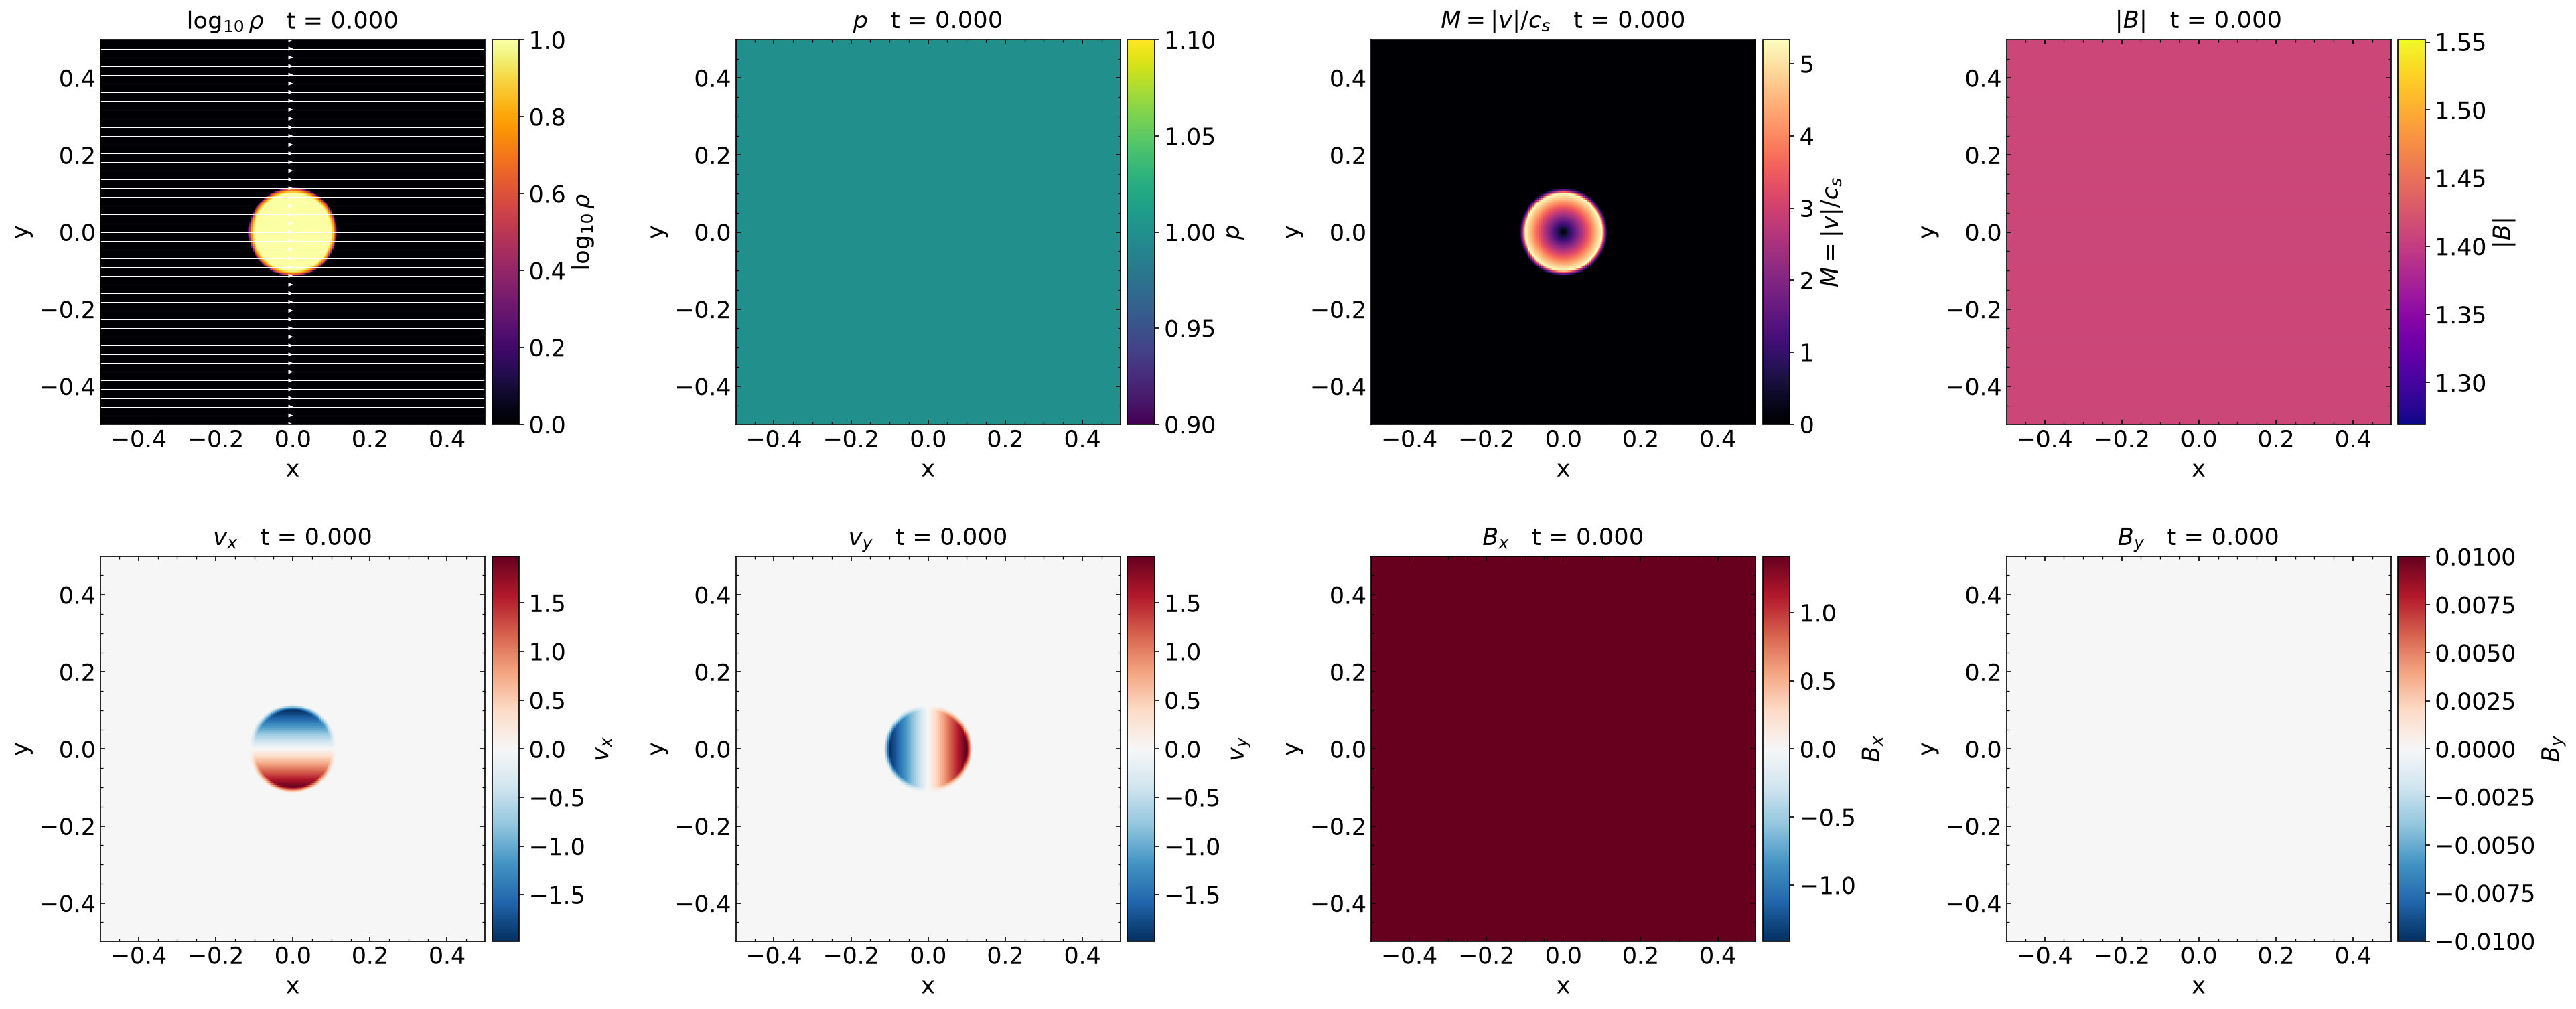

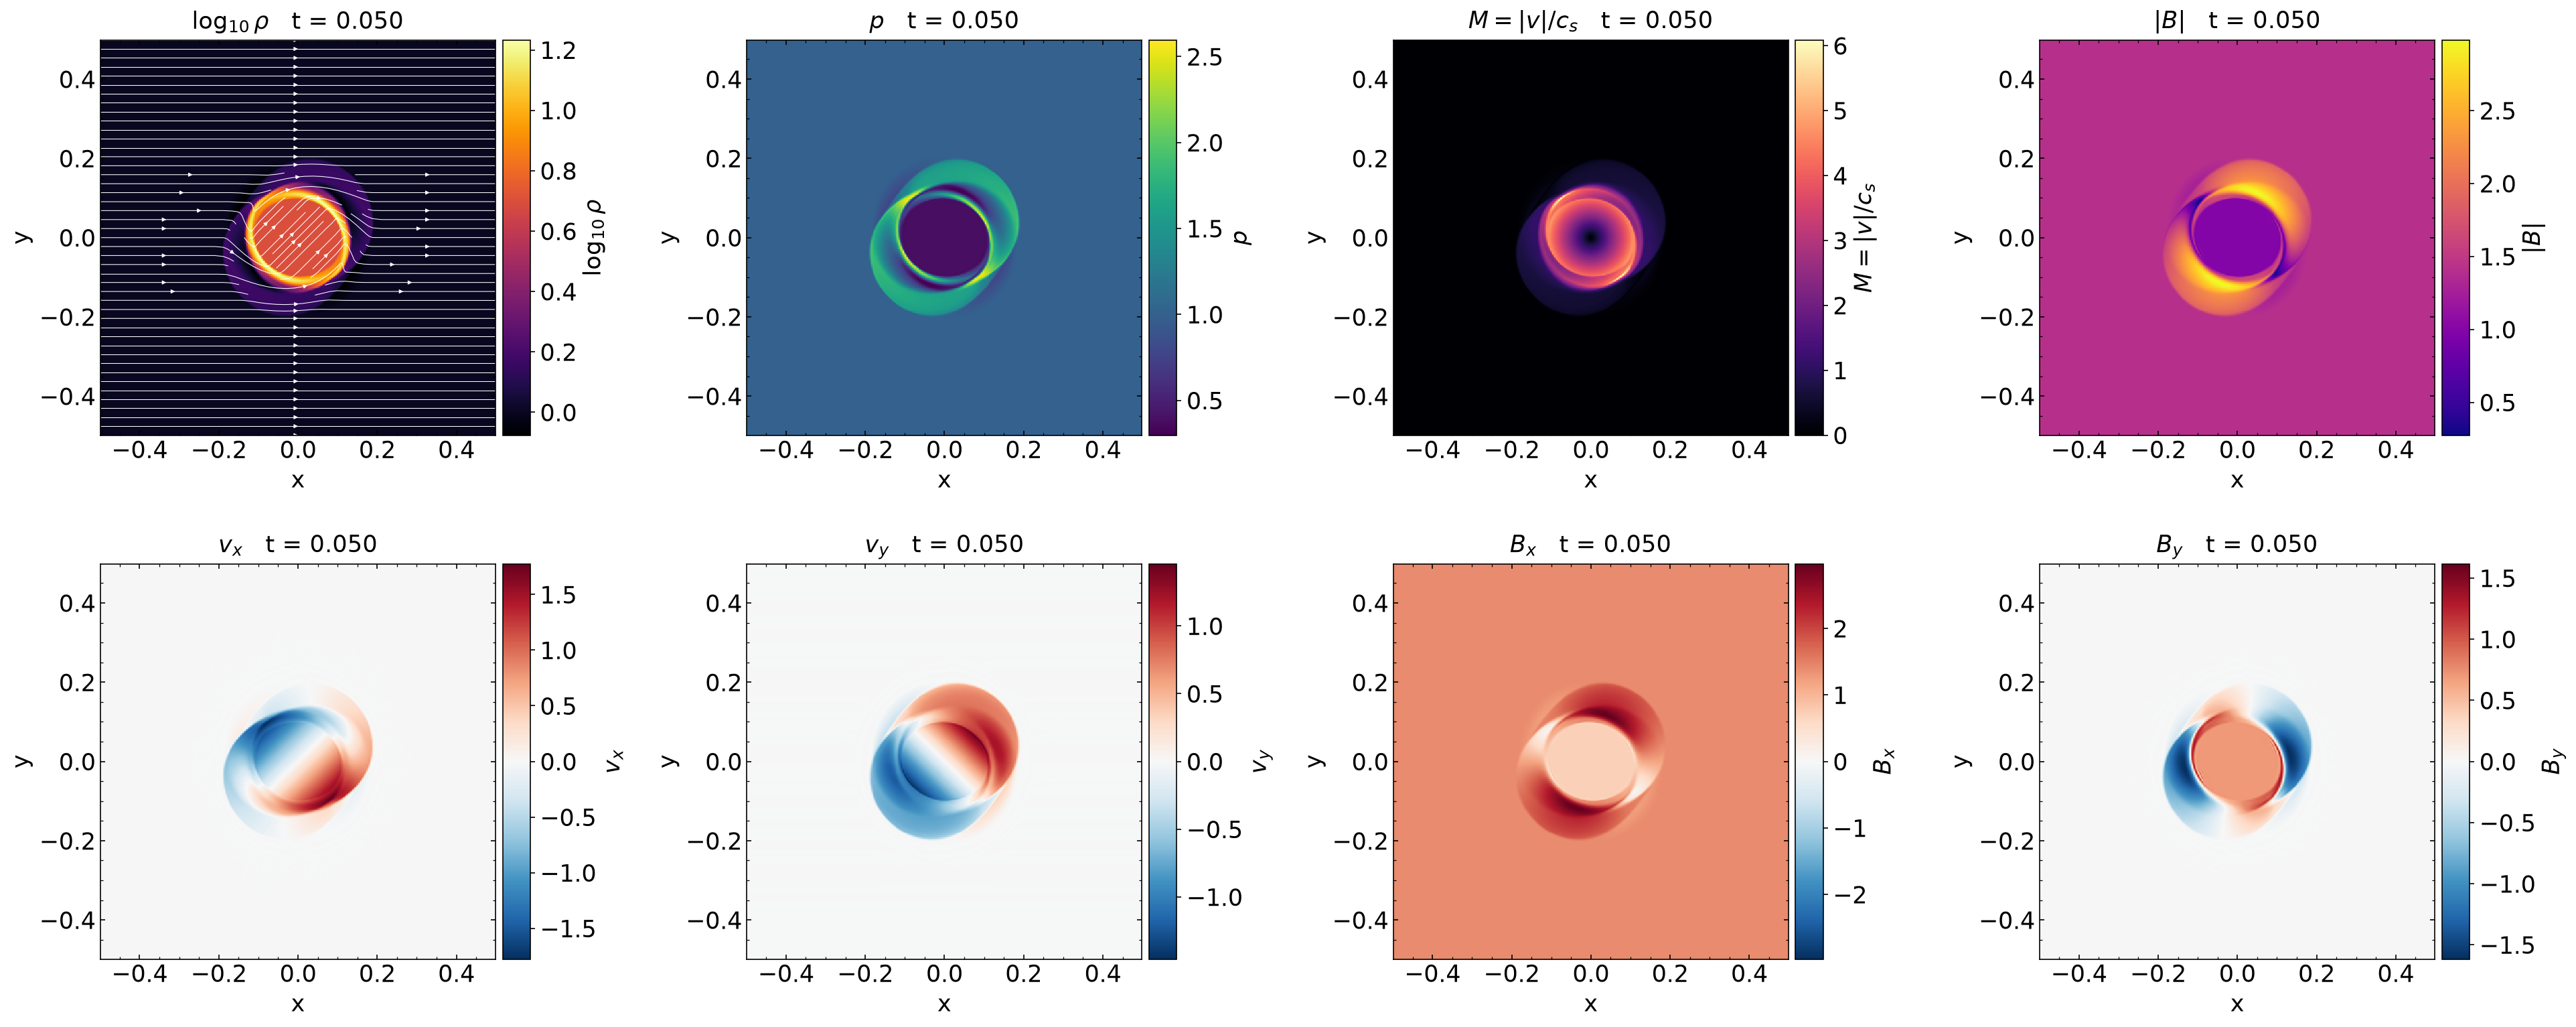

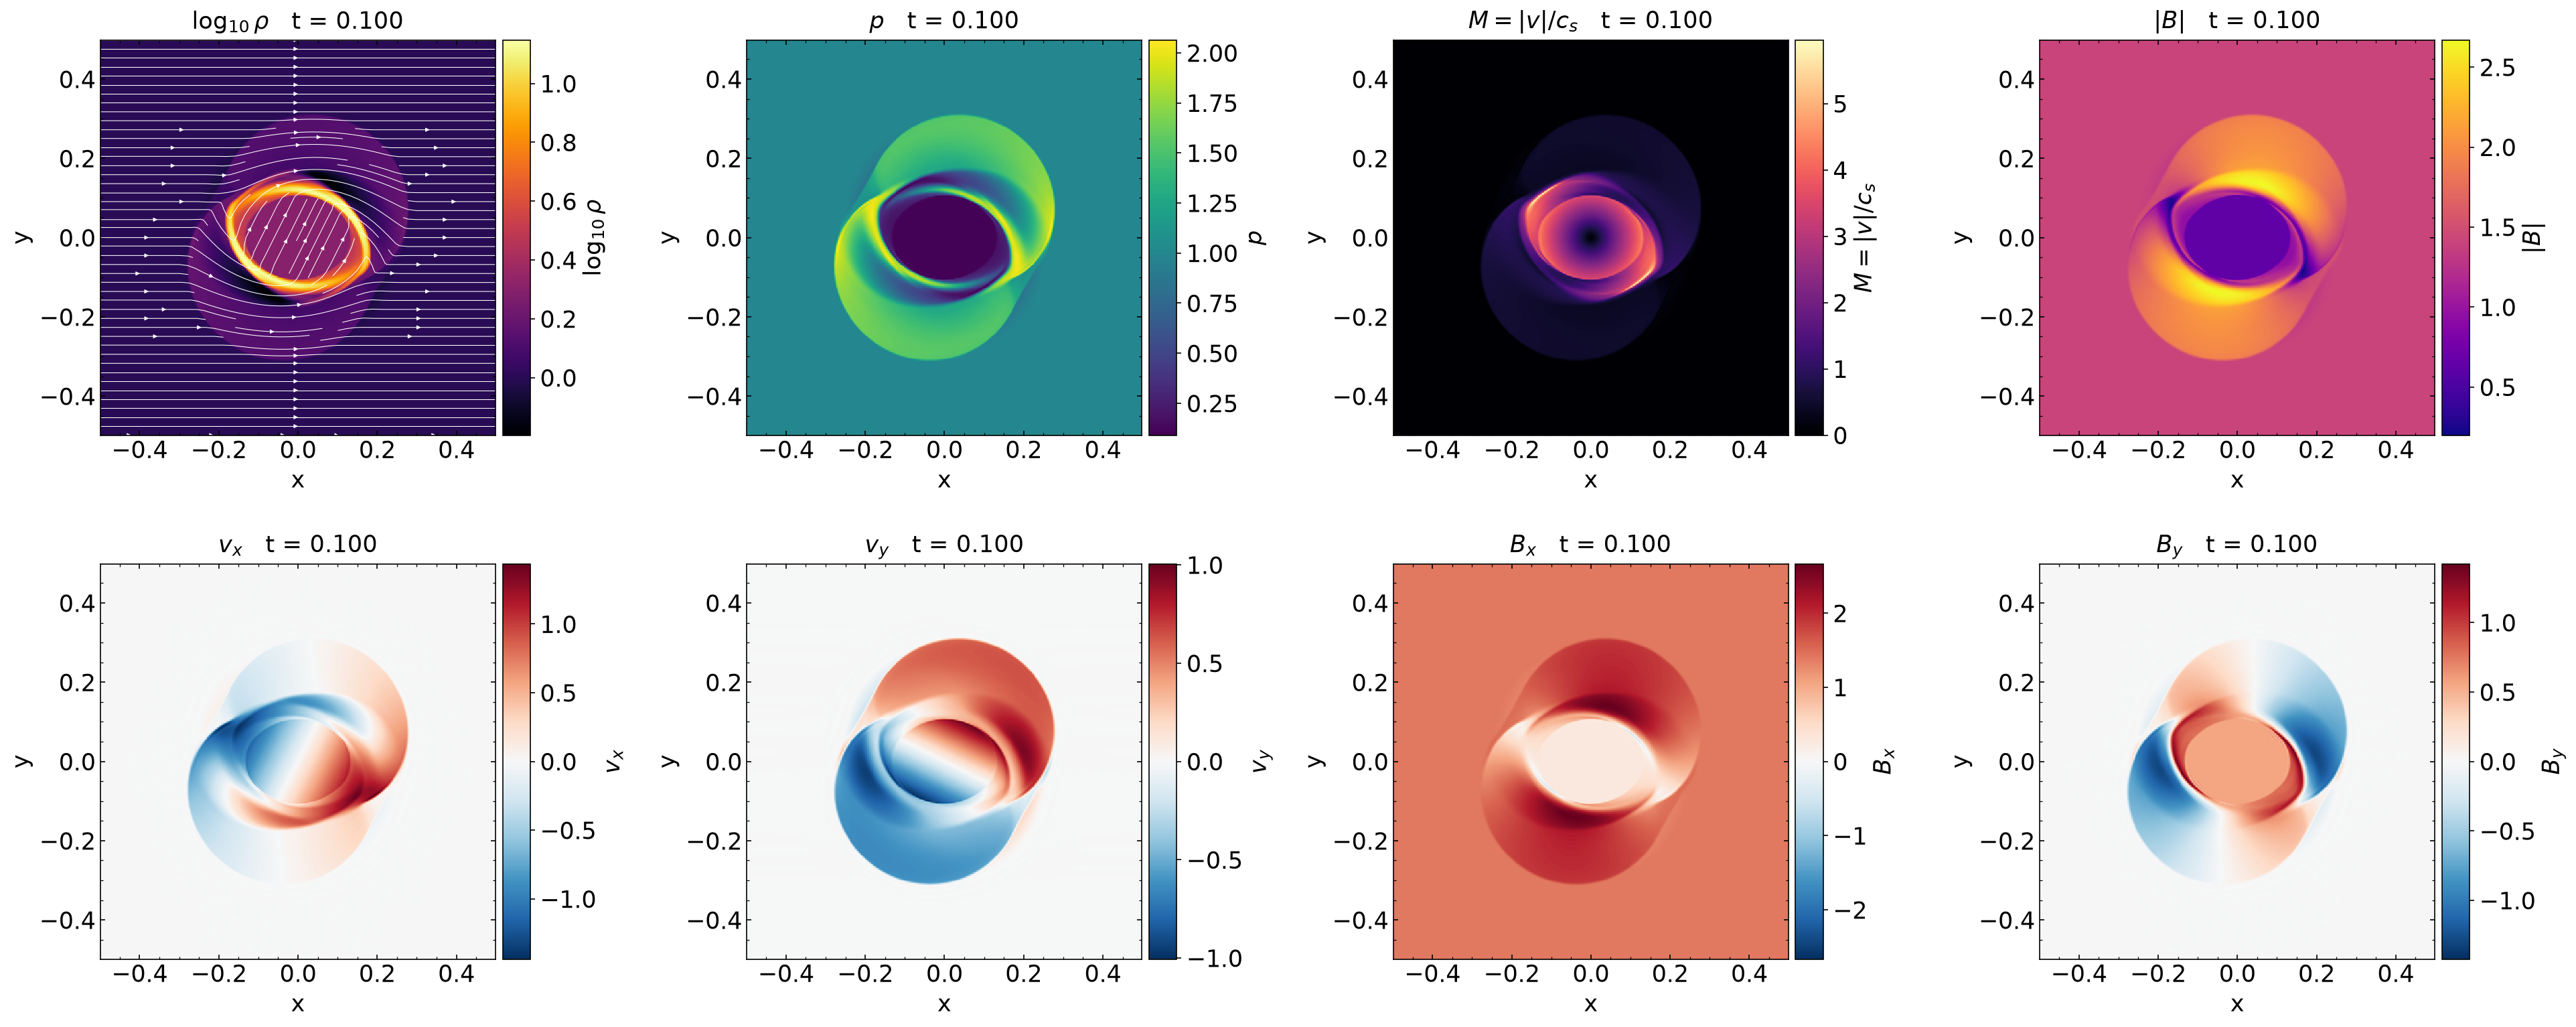

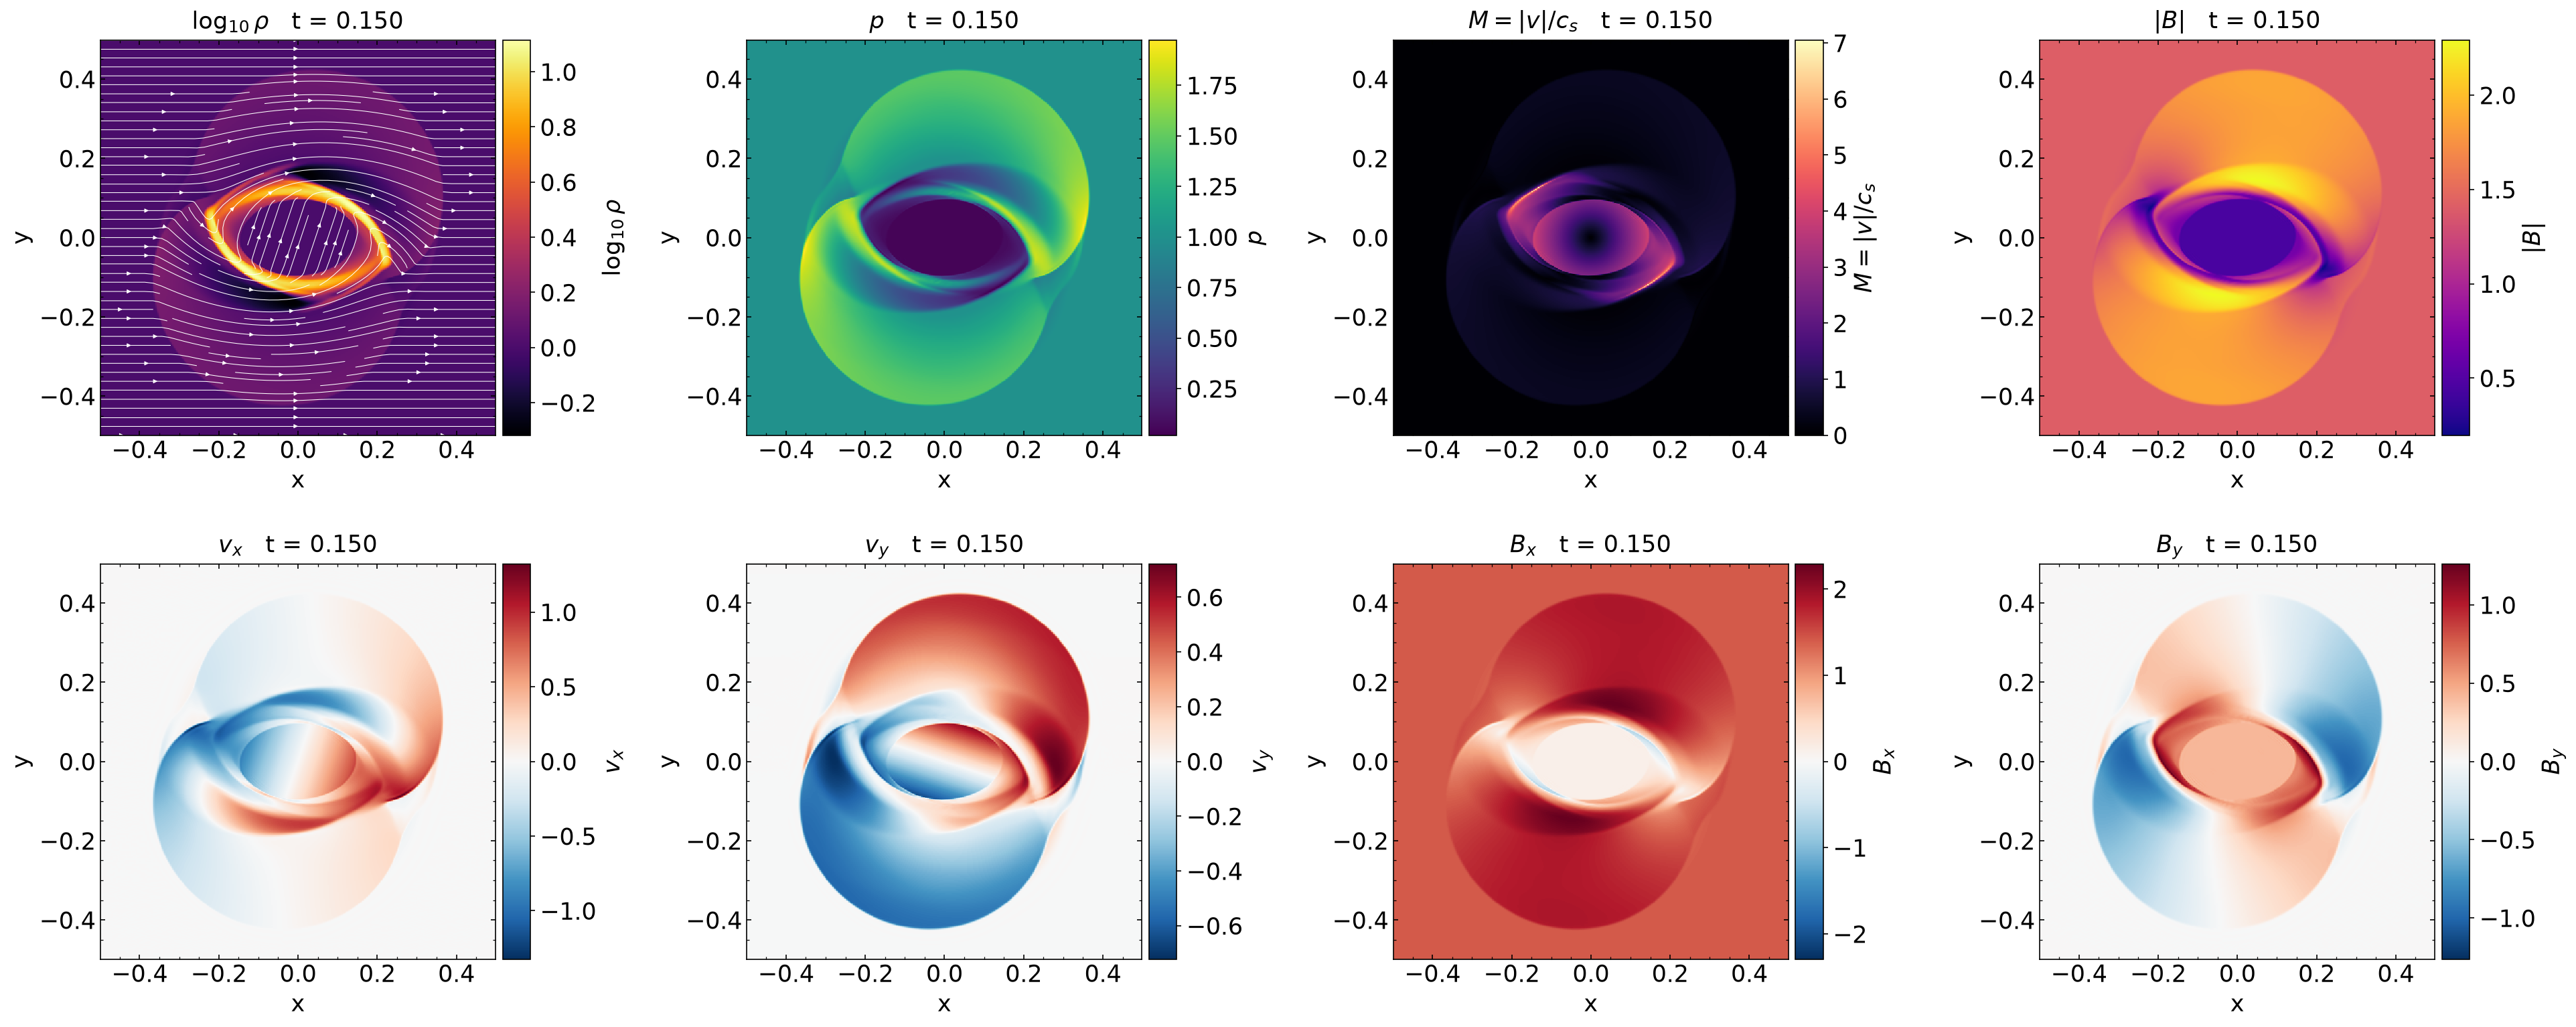

In [4]:
if RUN_PLUTO_PLOTS:
    run_script("plot_pluto.py")
for n in range(4):
    show(FIG / f"pluto_rotor_{n:04d}.png")

**Lectura de las figuras.** En $t=0$ solo hay el disco que rota sobre el campo uniforme. En $t=0.05$ ya aparece la estructura torsional: $B_y$ cambia de signo alrededor del rotor y se forma el anillo denso. En $t=0.15$ el rotor se ha deformado en una elipse inclinada con un vacío de presión en el centro y dos lóbulos exteriores (los frentes rápidos), con $M_{\max}\approx7$ en el borde interno del anillo. La solución es simétrica bajo una rotación de 180° alrededor del origen: $\rho$, $p$, $B_x$, $B_y$ son pares y $\mathbf v$ es impar (se verifica numéricamente en la sección 5).

## 4. Reproducción en Python

### 4.1 El solver (`python/mhd_core.py`)

Se implementó un solver de volúmenes finitos 2.5D con la misma numérica que la configuración #01 de PLUTO (sección 1.6), compilado con *numba* (`@njit`, `parallel=True`). Los arreglos usan el orden `[x, y]` igual que pyPLUTO; hay dos celdas fantasma por lado. Las partes centrales se muestran a continuación.

In [5]:
print(inspect.getsource(mhd_core.hlld.py_func))

@njit(cache=True)
def hlld(wl, wr, F, S, gam):
    """
    Flujo HLLD (Miyoshi & Kusano 2005) en la direccion x.
    wl, wr : estados primitivos [rho, vx, vy, vz, Bx, By, Bz, p]  (Bx identico en ambos)
    F      : salida, flujo de las conservadas [D, Mx, My, Mz, Bx, By, Bz, E]
    S      : buffer de trabajo (8, 8)
    """
    rL = wl[0]; uL = wl[1]; vL = wl[2]; wL = wl[3]; byL = wl[5]; bzL = wl[6]; pL = wl[7]
    rR = wr[0]; uR = wr[1]; vR = wr[2]; wR = wr[3]; byR = wr[5]; bzR = wr[6]; pR = wr[7]
    bx = wl[4]
    bx2 = bx * bx
    B2L = bx2 + byL * byL + bzL * bzL
    B2R = bx2 + byR * byR + bzR * bzR
    ptL = pL + 0.5 * B2L
    ptR = pR + 0.5 * B2R
    eL = pL / (gam - 1.0) + 0.5 * rL * (uL * uL + vL * vL + wL * wL) + 0.5 * B2L
    eR = pR / (gam - 1.0) + 0.5 * rR * (uR * uR + vR * vR + wR * wR) + 0.5 * B2R

    # velocidades magnetosonicas rapidas
    a2 = gam * pL / rL
    ct = a2 + B2L / rL
    cfL = np.sqrt(0.5 * (ct + np.sqrt(max(ct * ct - 4.0 * a2 * bx2 / rL, 0.0))))
    a2 

In [6]:
print(inspect.getsource(mhd_core.update.py_func))
print(inspect.getsource(mhd_core.MHDSolver2D._euler))
print(inspect.getsource(mhd_core.MHDSolver2D.step))

@njit(parallel=True, cache=True)
def update(Un, bxn, byn, fx, fy, dt, dx, dy, ng, nx, ny):
    cx = dt / dx
    cy = dt / dy
    # EMF en esquinas (lado inferior-izquierdo de la celda (ic,jc)); promedio aritmetico
    # Ez(cara x) = -F_x(By) = -fx[5];   Ez(cara y) = +F_y(Bx) = fy[4]
    ez = np.zeros((nx + 2 * ng + 1, ny + 2 * ng + 1))
    for ic in prange(ng, ng + nx + 1):
        for jc in range(ng, ng + ny + 1):
            ez[ic, jc] = 0.25 * (-fx[5, ic, jc - 1] - fx[5, ic, jc]
                                 + fy[4, ic - 1, jc] + fy[4, ic, jc])
    for i in prange(ng, ng + nx + 1):
        for j in range(ng, ng + ny):
            bxn[i, j] -= cy * (ez[i, j + 1] - ez[i, j])
    for i in prange(ng, ng + nx):
        for j in range(ng, ng + ny + 1):
            byn[i, j] += cx * (ez[i + 1, j] - ez[i, j])
    # variables de celda (D, M, Bz, E)
    for i in prange(ng, ng + nx):
        for j in range(ng, ng + ny):
            for v in (0, 1, 2, 3, 6, 7):
                Un[v, i, j] -=

Observaciones de diseño:
- **Barrido en $y$ por rotación de variables.** Se reutiliza el HLLD de dirección $x$ rotando $(x,y,z)\to(y,z,x)$; el flujo de $B_x$ en la dirección $y$ es directamente $E_z$ en las caras $y$.
- **Campo normal escalonado.** En cada cara, el solver de Riemann usa el $B$ normal almacenado (único en la cara) y reconstruye solo las componentes tangenciales, como hace PLUTO con CT.
- **Paso de tiempo.** $\Delta t=\mathrm{CFL}/\max_{i,j}\max_d\big[(|v_d|+c_{f,d})/\Delta_d\big]$ con crecimiento máximo de $1.1$ por paso desde $\Delta t_0=10^{-6}$. Esto es una inferencia a partir del número de pasos de PLUTO (589 frente a 1119 con la suma de direcciones); el código fuente de PLUTO no se inspeccionó. El resultado son 639 pasos.
- **Salvaguardas.** Si la reconstrucción da $\rho\le0$ o $p\le0$ en una cara, se usan los valores de celda (primer orden); piso de presión $10^{-10}$.

### 4.2 Verificación del solver

Antes de usarlo en el rotor se probó con tres pruebas independientes (`python/tests_solver.py`):
1. **Consistencia del HLLD:** con estados iguales a ambos lados el flujo debe coincidir con el flujo físico.
2. **Onda de Alfvén circular** (solución exacta no lineal), orientada en $x$ y en $y$, en malla periódica: se mide la convergencia tras un período.
3. **Brio–Wu** (con $B_z\neq0$) orientado en $x$ y rotado 90° en el plano a $y$: ambos deben coincidir a precisión de máquina, lo que prueba el barrido en $y$ y la CT.

In [7]:
if RUN_TESTS:
    import tests_solver as ts
    ok = [ts.test_hlld_consistency(), ts.test_alfven(), ts.test_briowu()]
    print("RESULTADO:", "TODO OK" if all(ok) else ok)
else:
    print("RUN_TESTS = False")

[1] HLLD consistencia: max|F - F_fisico| = 1.11e-16
[2] Alfven en x: L1 = 3.543e-03, 1.178e-03, 3.359e-04, 8.933e-05  | orden = 1.59, 1.81, 1.91  | max|divB| = 0.0e+00
[2] Alfven en y: L1 = 3.543e-03, 1.178e-03, 3.359e-04, 8.933e-05  | orden = 1.59, 1.81, 1.91  | max|divB| = 0.0e+00
[3] Brio-Wu x vs y (rotado 90 grados): max|diferencia| = 6.05e-15;  rho in [0.1156, 1.0007], max|vz|=0.806, max|divB| = 0.0e+00
RESULTADO: TODO OK


Resultado esperado (obtenido al desarrollar el solver): el HLLD reproduce el flujo físico con error $\sim10^{-16}$; la onda de Alfvén converge con orden $\approx1.9$ (errores $L_1$: $3.2\times10^{-3}$, $1.0\times10^{-3}$, $2.8\times10^{-4}$, $7.4\times10^{-5}$ para $N=16,32,64,128$), idéntico en $x$ e $y$; y Brio–Wu coincide en ambas orientaciones a $\sim10^{-14}$, con $\max|\nabla\cdot\mathbf B|=0$.

### 4.3 Ejecución del rotor

In [8]:
if RUN_SOLVER:
    t0 = time.time()
    run_script("run_rotor.py", "-n", str(N))
    print(f"tiempo total: {time.time()-t0:.0f} s")
diag_table(PY_DIR)

| snapshot | t | ρ mín | ρ máx | p mín | p máx | Mach máx | masa | máx\|∇·B\| |
|---|---|---|---|---|---|---|---|---|
| 0000 | 0.00000 | 1.0000 | 10.0000 | 1.0000 | 1.0000 | 5.333 | 1.327265 | 0.0e+00 |
| 0001 | 0.04985 | 0.8395 | 17.0341 | 0.2970 | 2.5863 | 6.089 | 1.327265 | 5.2e-12 |
| 0002 | 0.09990 | 0.6374 | 14.0635 | 0.0904 | 2.0648 | 5.969 | 1.327265 | 7.1e-12 |
| 0003 | 0.15000 | 0.4810 | 13.0435 | 0.0196 | 1.9750 | 7.084 | 1.327265 | 9.2e-12 |

### 4.4 Mapas de la solución en Python

Mismos paneles que en la sección 3.4, con los **mismos límites de color que PLUTO** (para que las figuras sean directamente comparables). Se generan con `python/plot_python.py`.

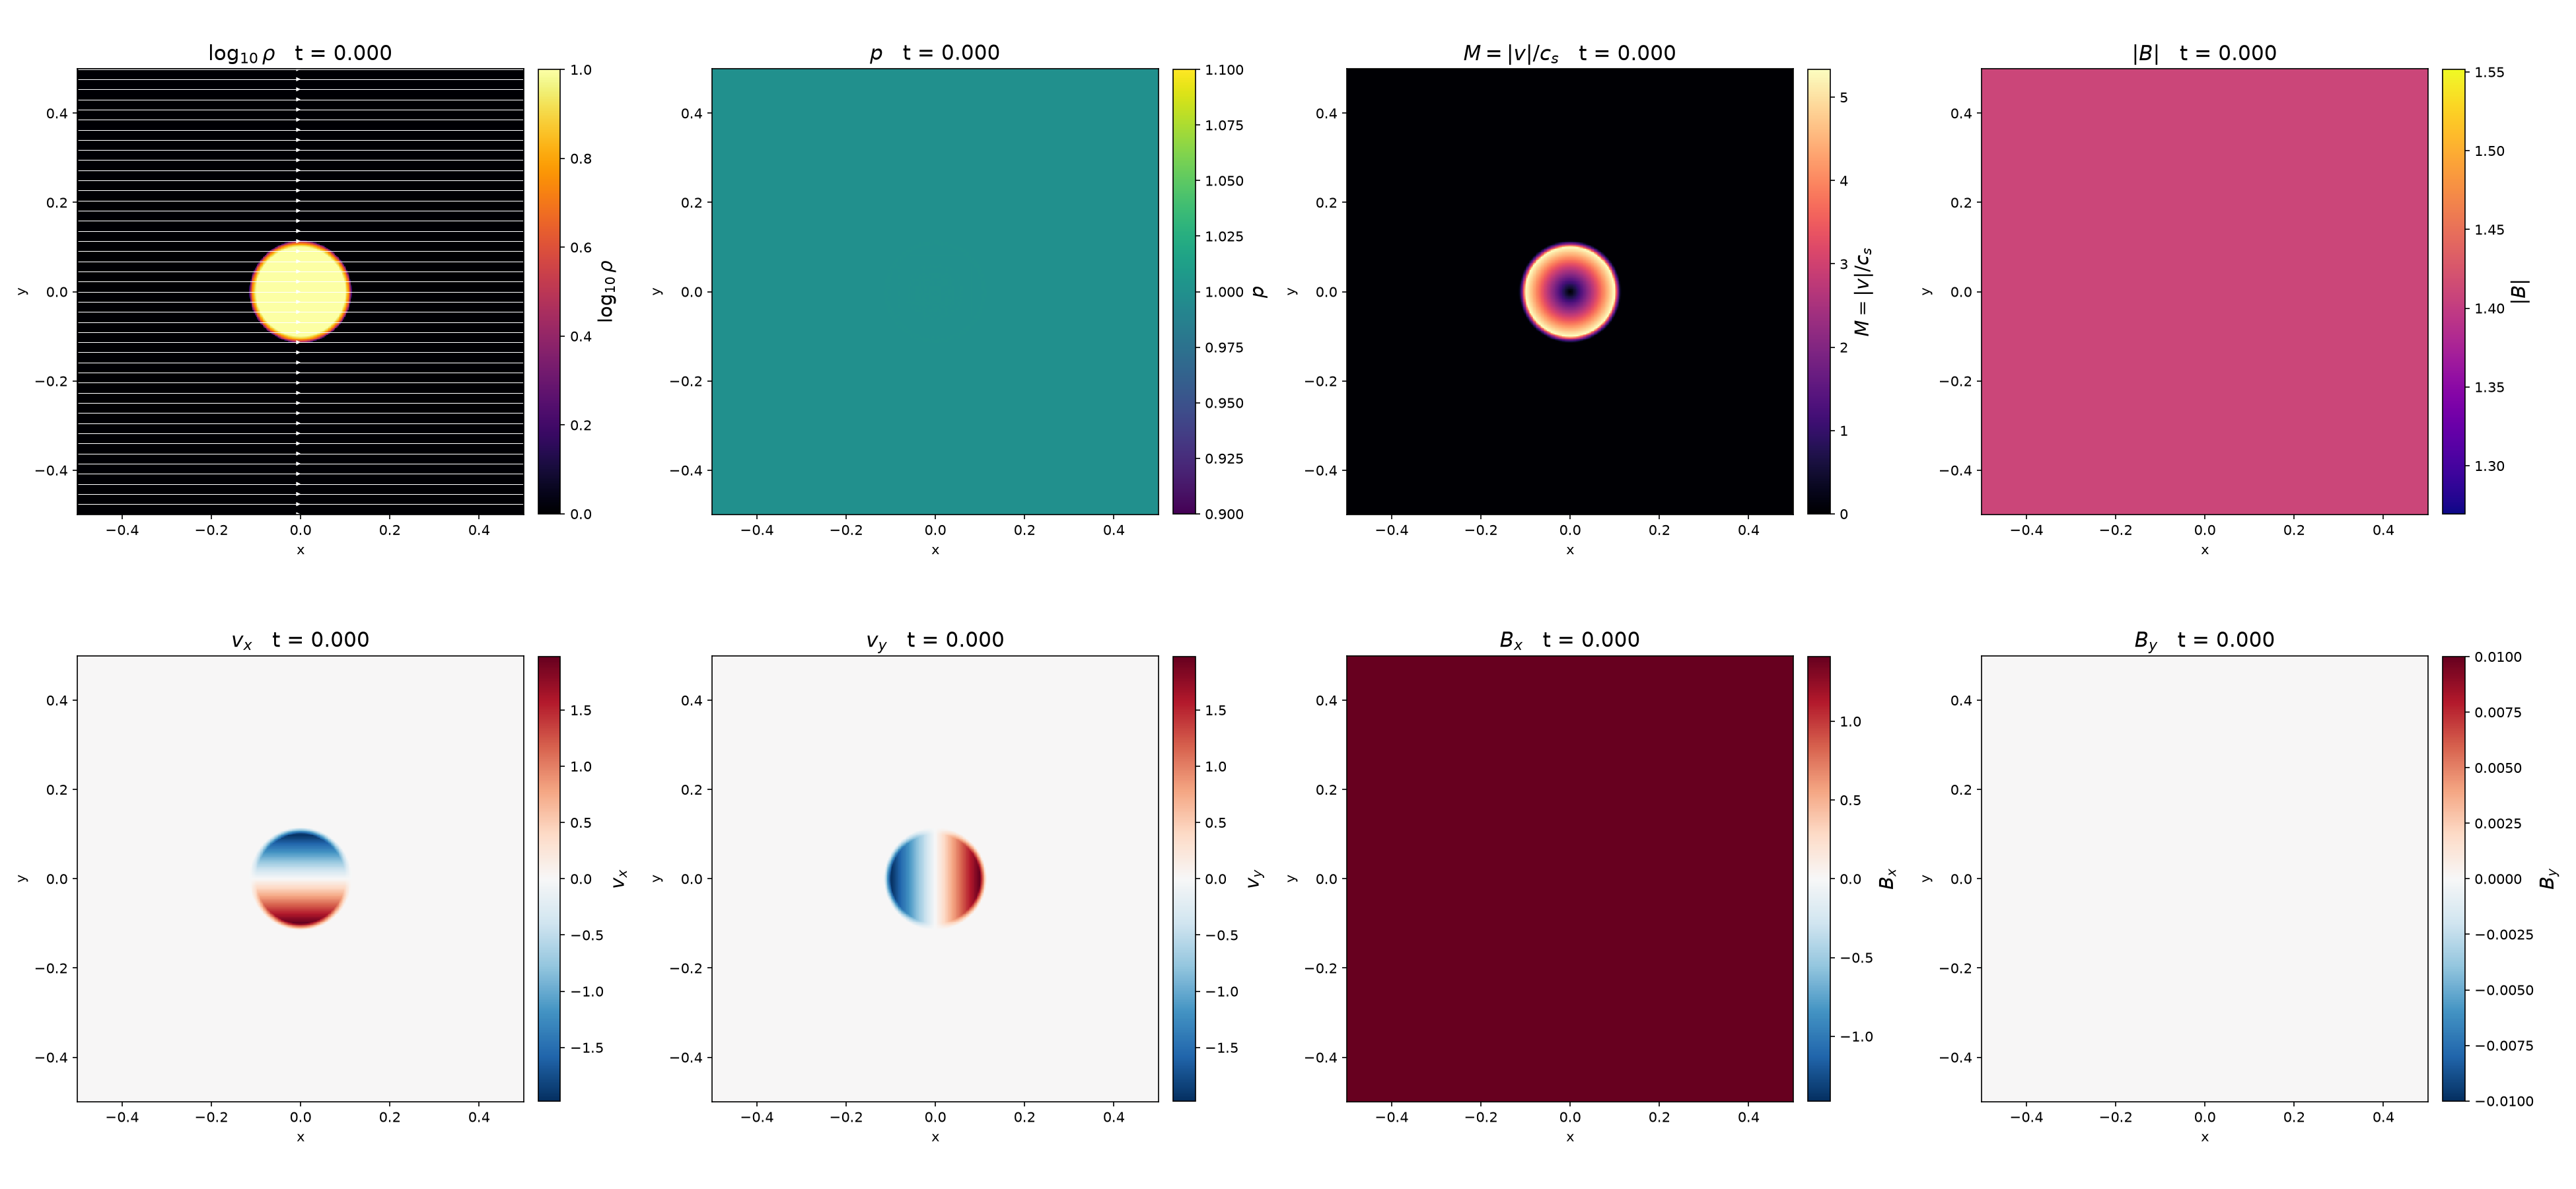

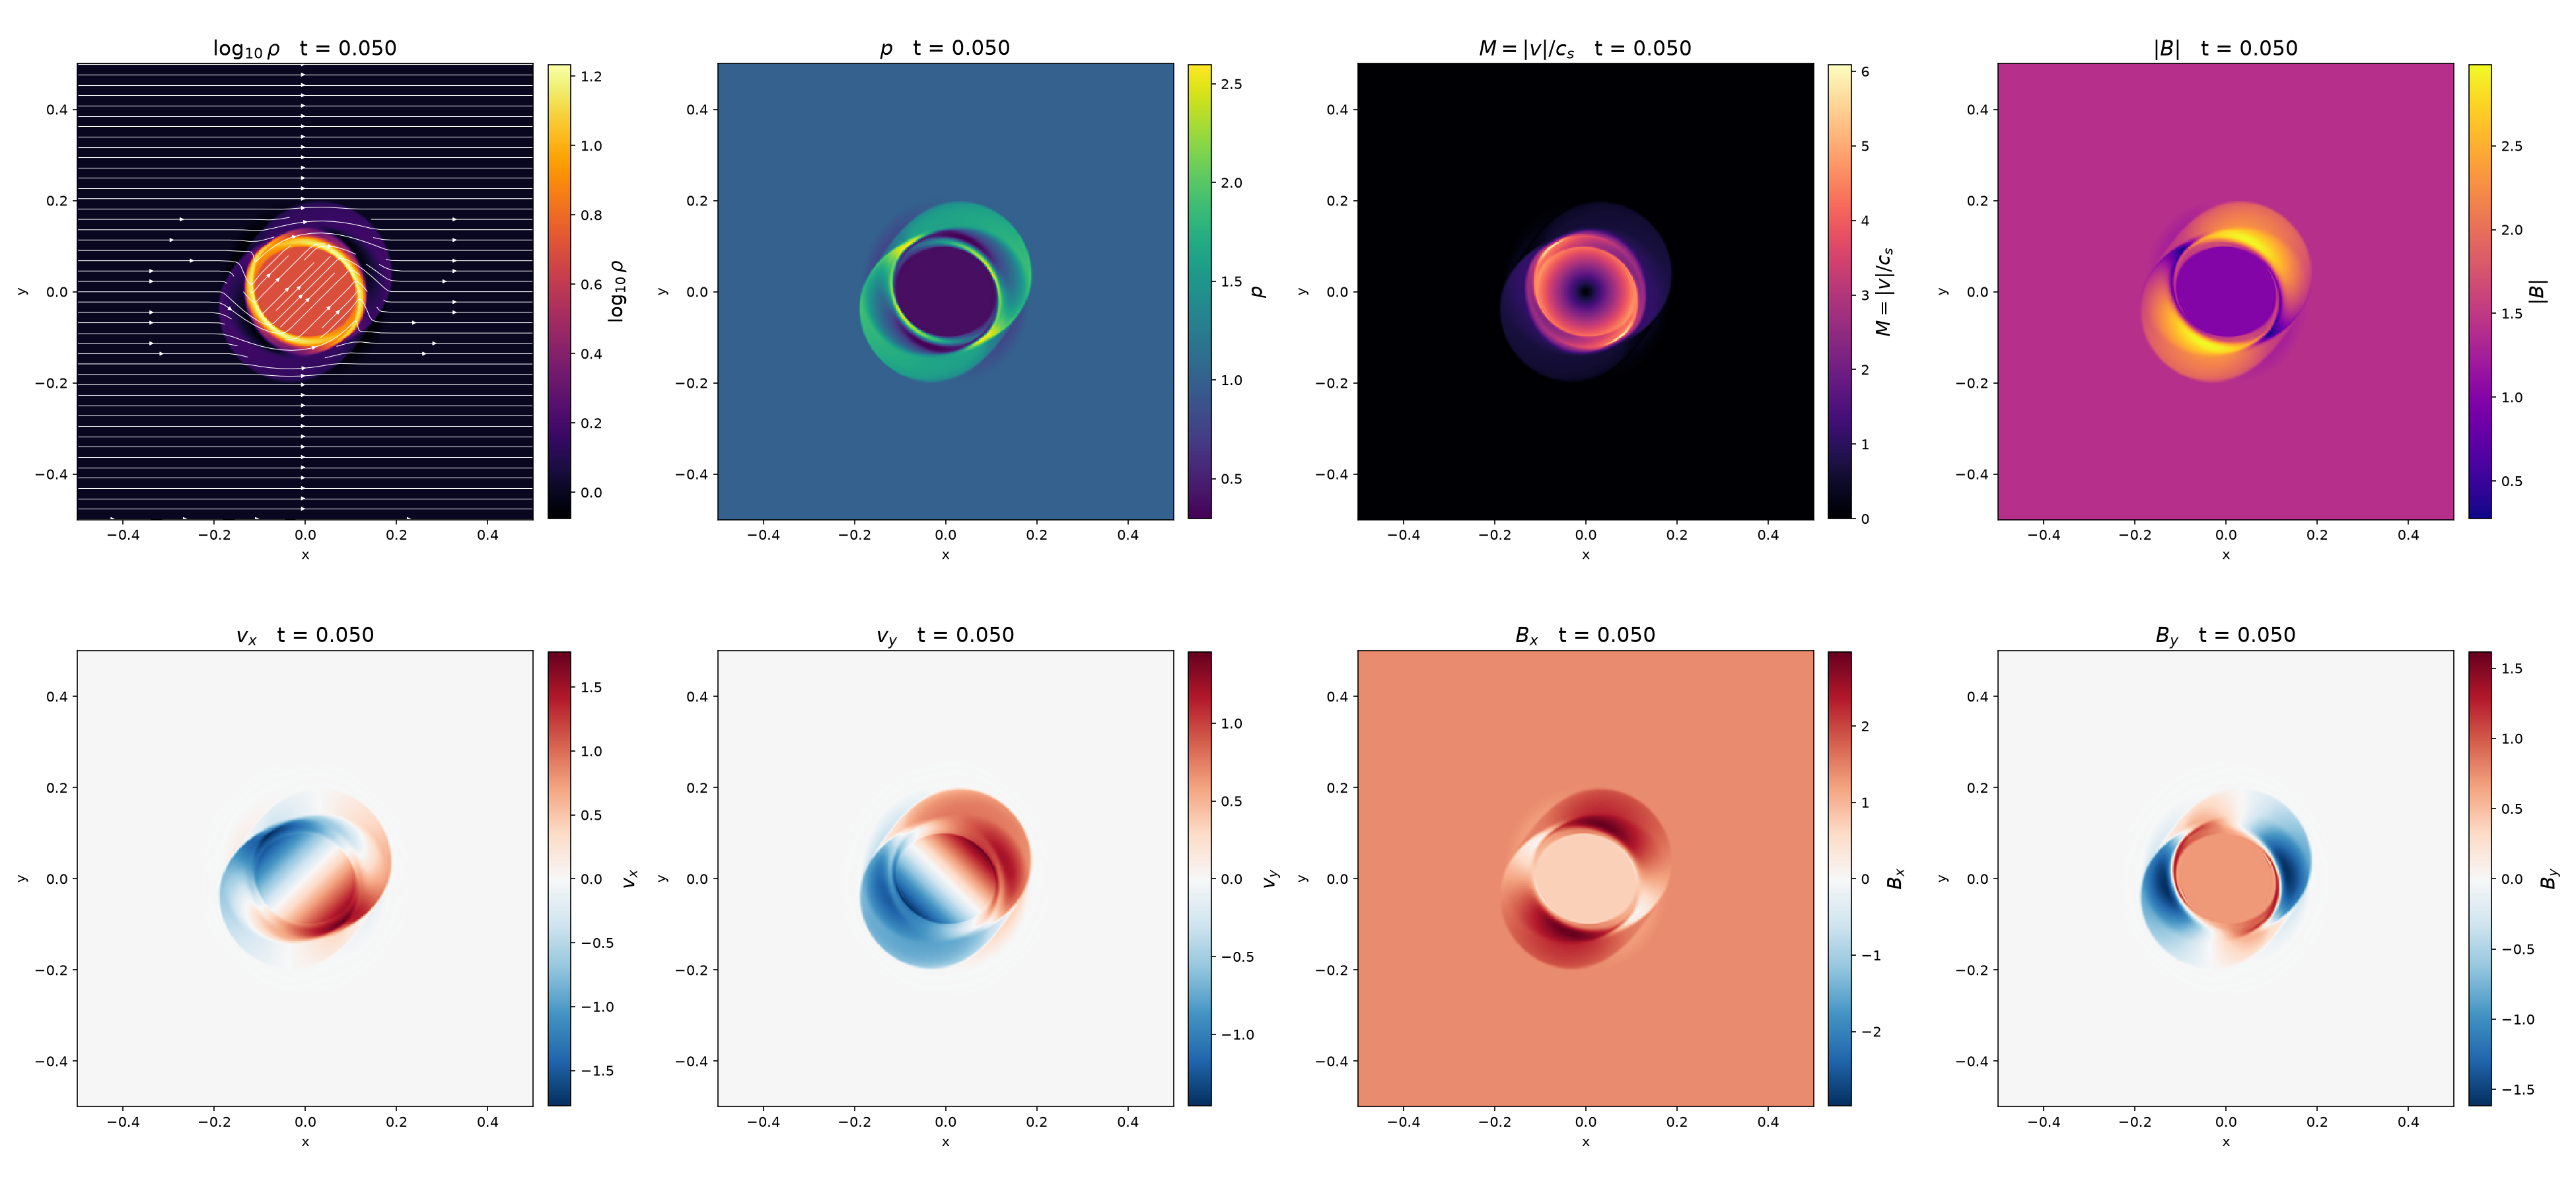

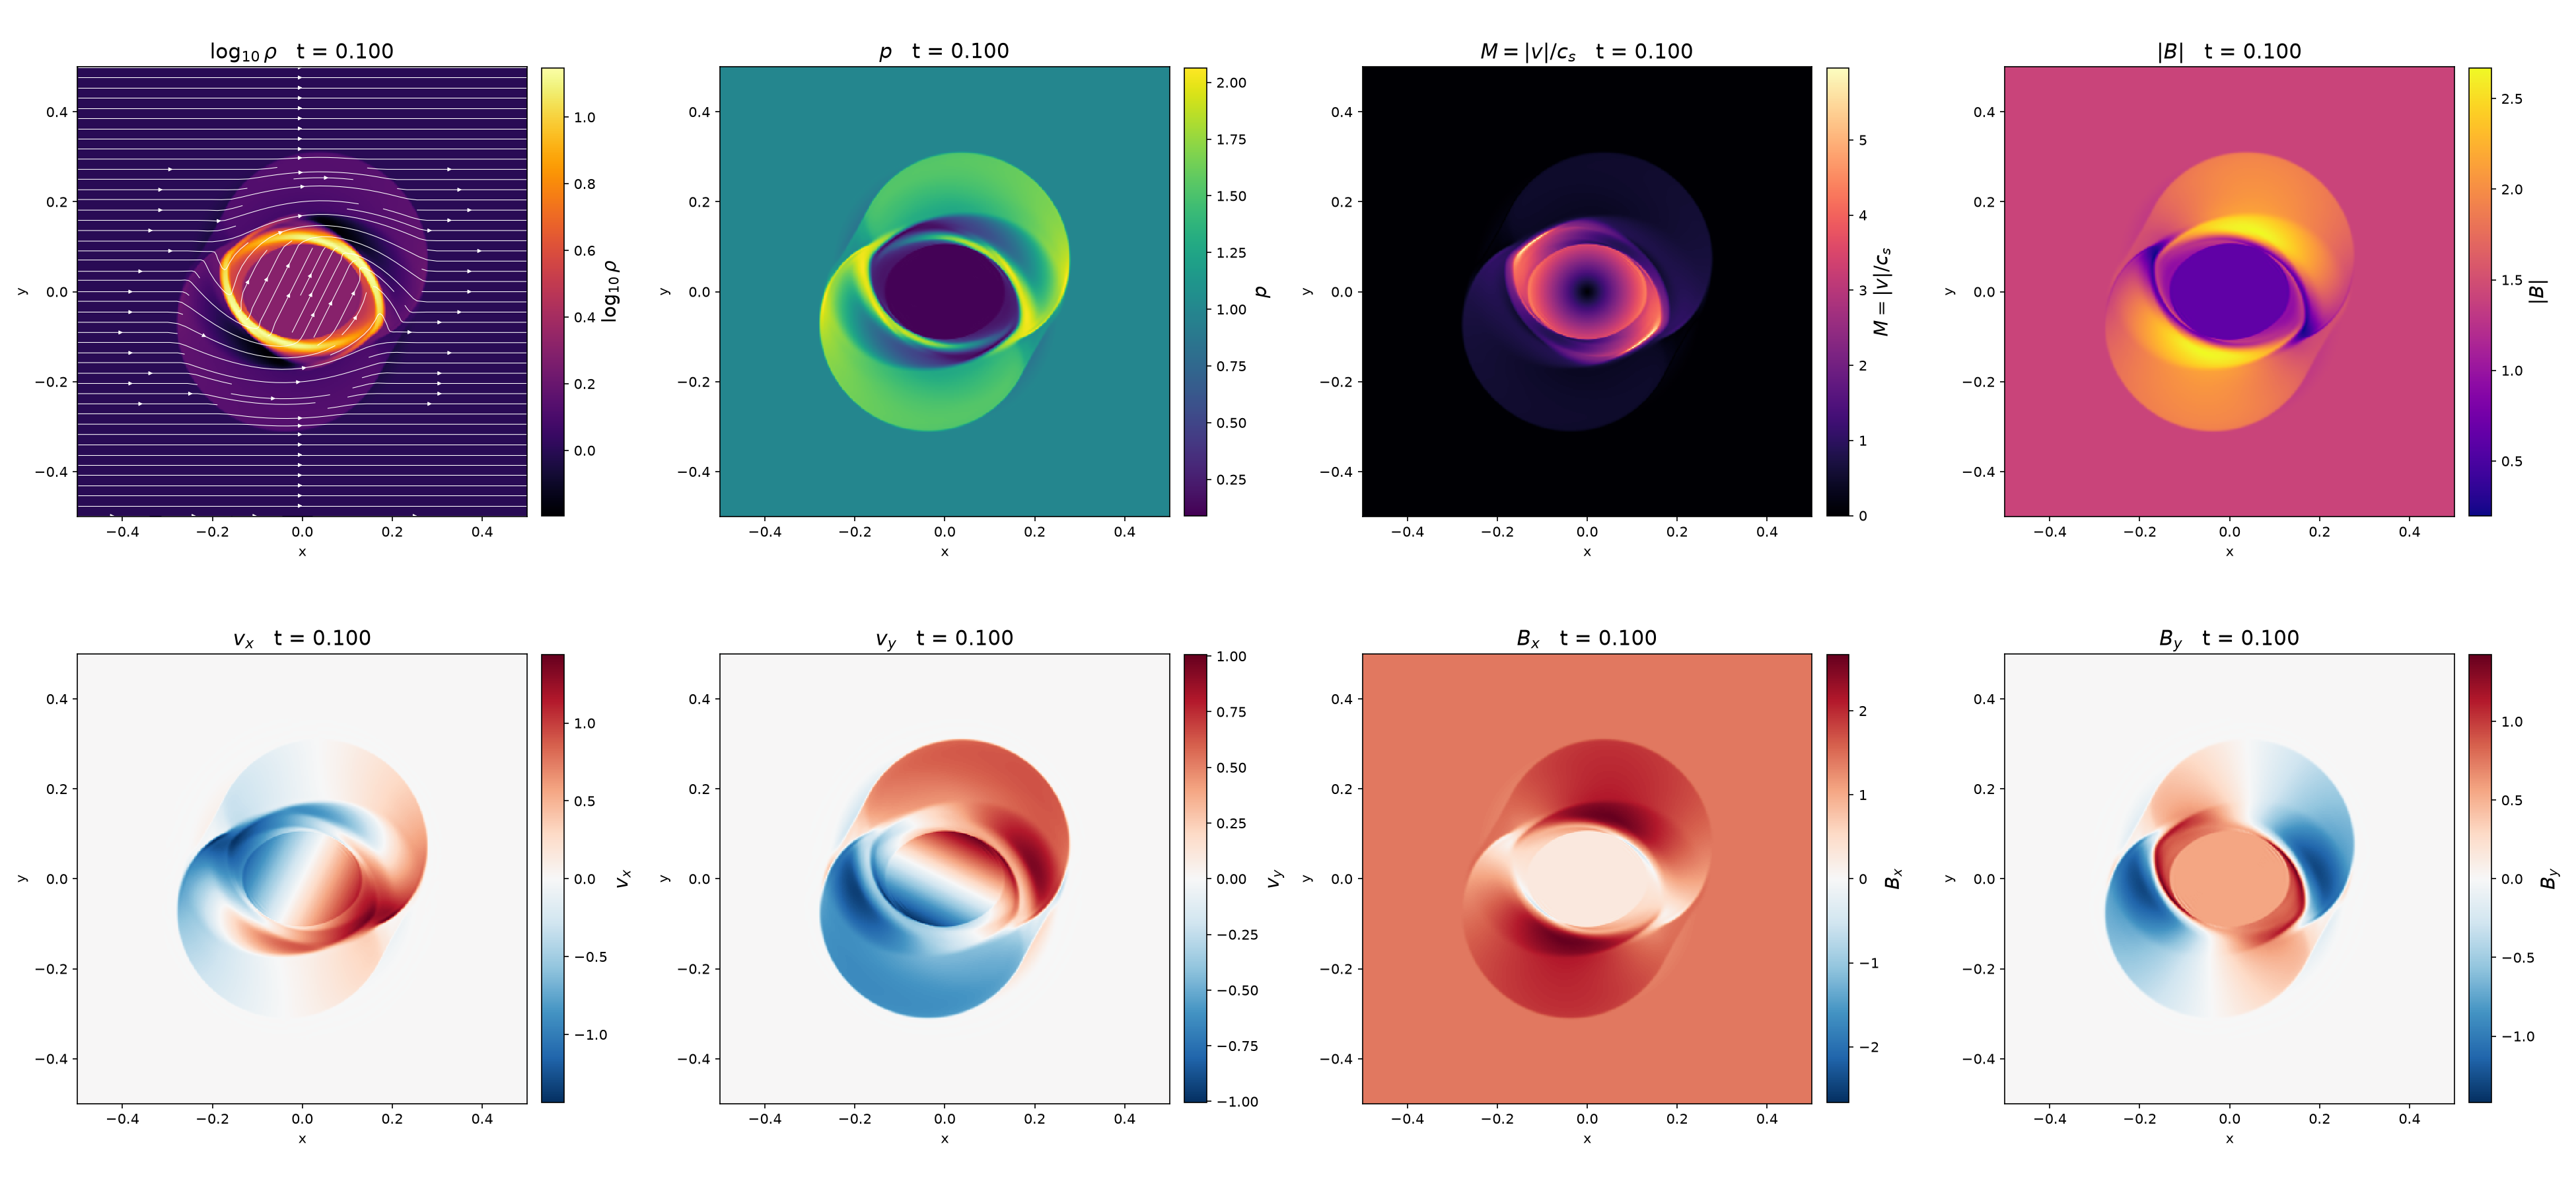

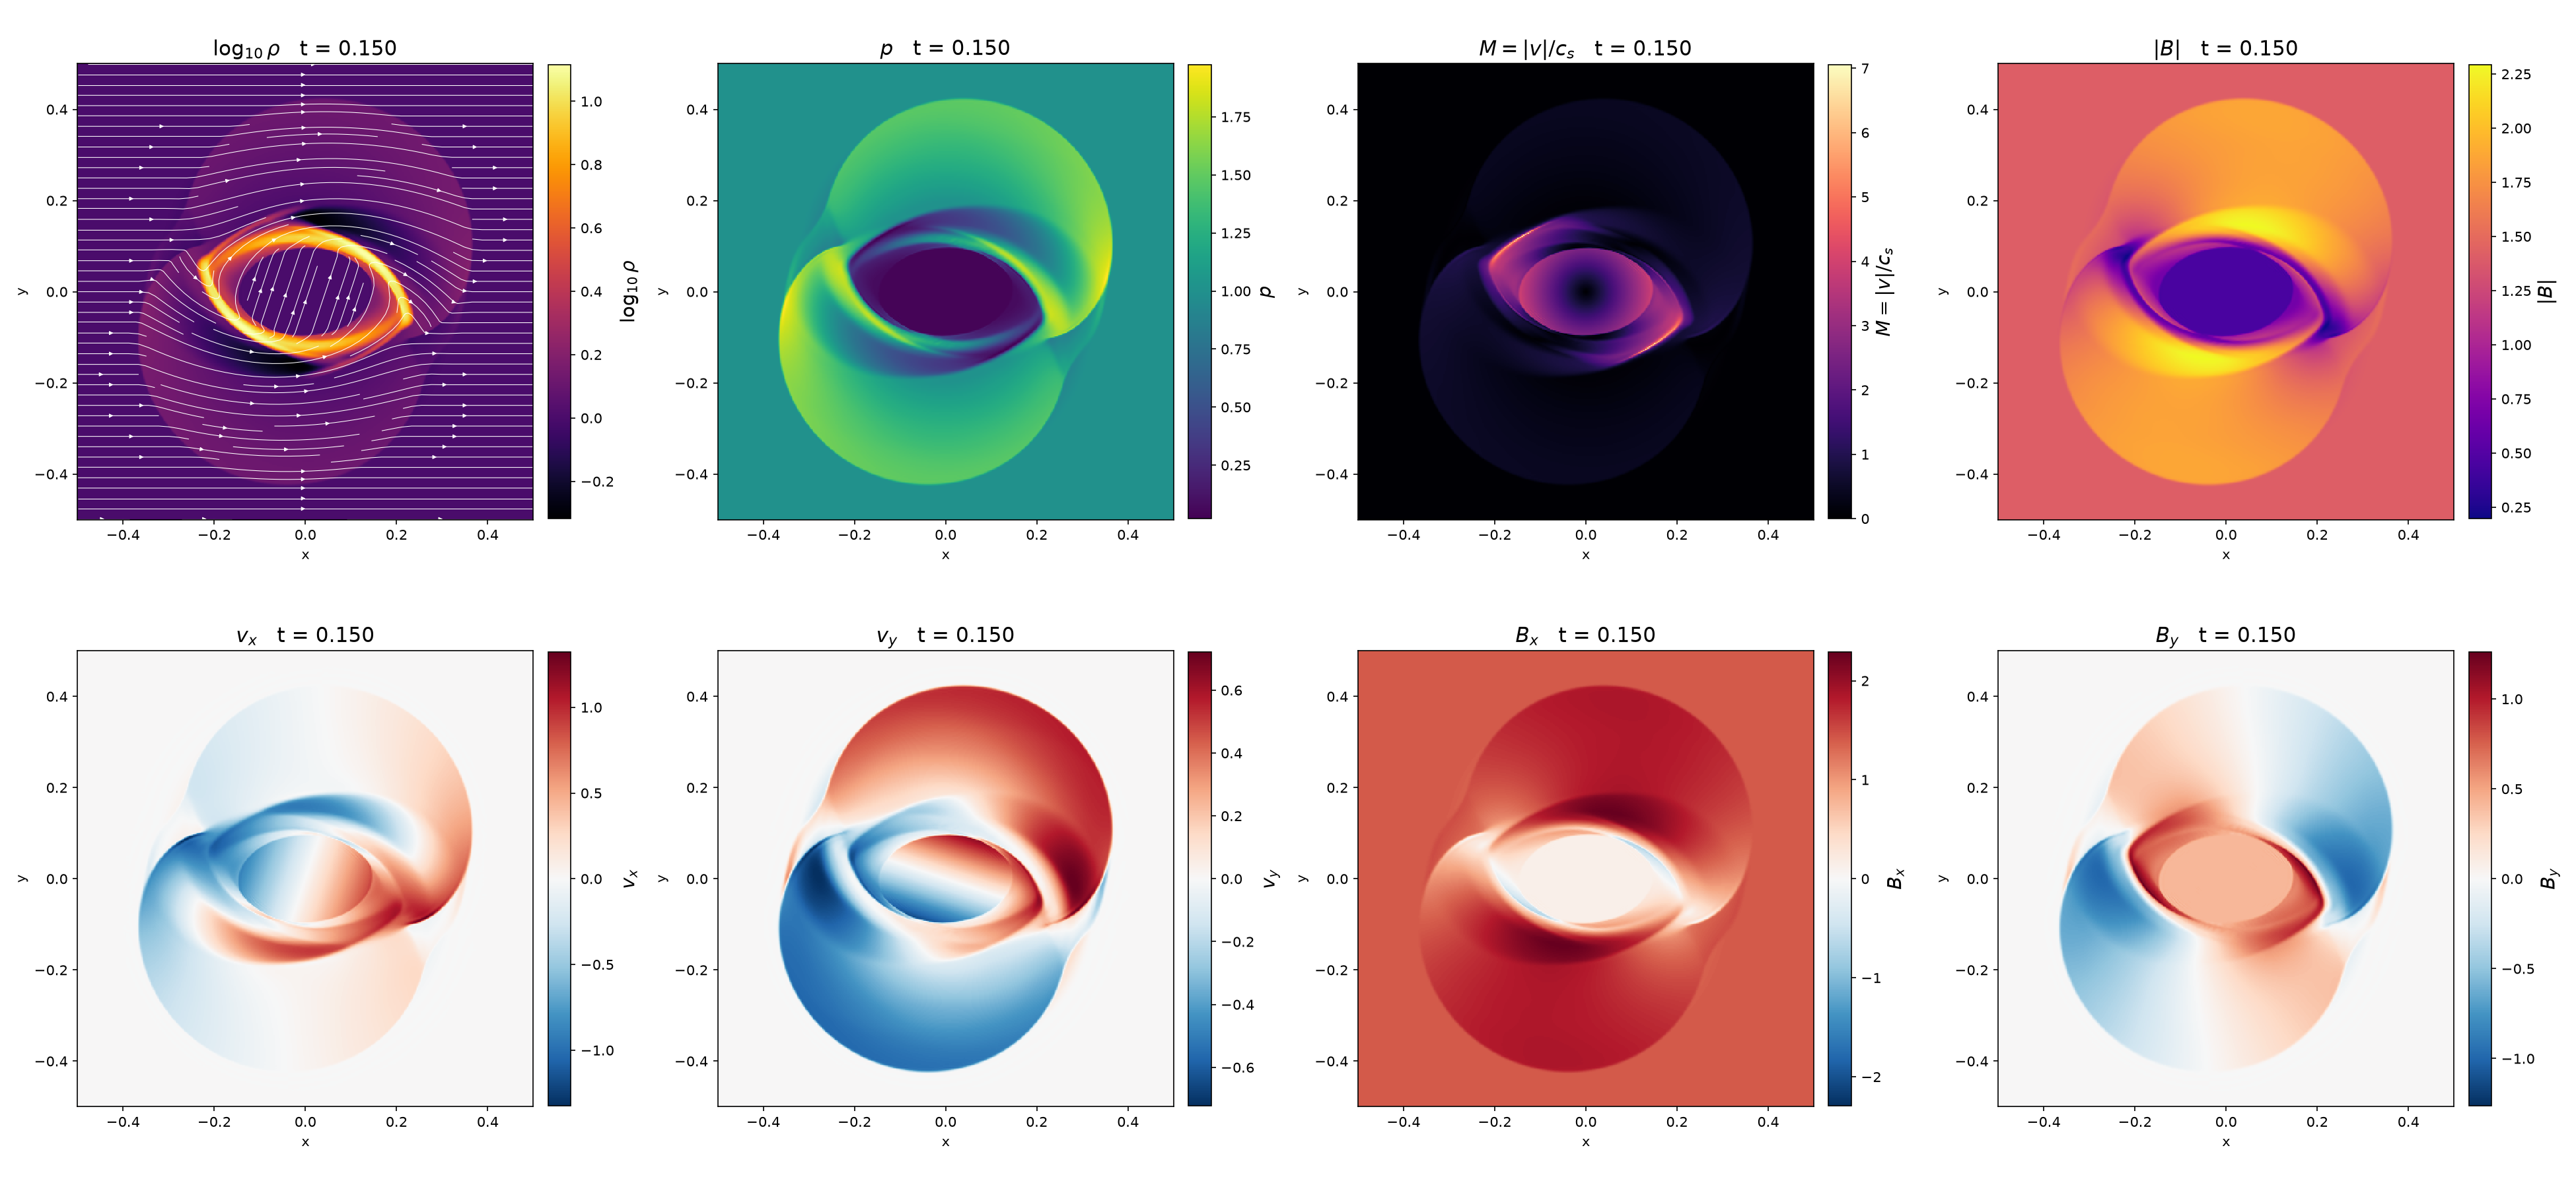

In [9]:
if RUN_SOLVER or not (FIG / f"python_rotor_N{N}_0003.png").exists():
    run_script("plot_python.py", "-n", str(N), "--pluto", str(PLUTO_DIR))
for n in range(4):
    show(FIG / f"python_rotor_N{N}_{n:04d}.png")

## 5. Análisis comparativo PLUTO vs Python

### 5.1 Métricas

Para cada variable $q$ y cada snapshot se comparan los campos de Python ($a$) y de PLUTO ($b$) en la misma malla y el mismo instante:

$$
L_1=\frac{\sum|a-b|}{\sum|b|},\qquad L_2=\frac{\sqrt{\sum(a-b)^2}}{\sqrt{\sum b^2}},\qquad
L_\infty/\text{rango}=\frac{\max|a-b|}{\max b-\min b},\qquad P_{99}/\text{rango}=\frac{\text{percentil}_{99}|a-b|}{\max b-\min b}.
$$

El $L_1$ y $L_2$ relativos de $B_x$ y $|\mathbf B|$ están suavizados por el fondo uniforme $B_x=1.41$ en el denominador; para esas variables conviene leer también `L1_abs` en el CSV. La comparación $L_\infty$/$P_{99}$ separa el error "típico" del error en pocas celdas de choque.

In [10]:
csvp = REP / f"errores_N{N}.csv"
if RUN_COMPARE or not csvp.exists():
    run_script("compare.py", "--pluto", str(PLUTO_DIR), "--python", str(PY_DIR))
rows = list(csv.DictReader(open(csvp)))
names = {"rho": "ρ", "prs": "p", "vx1": "v_x", "vx2": "v_y", "Bx1": "B_x", "Bx2": "B_y", "mach": "Mach", "bmag": "\\|B\\|"}
fmt = lambda v: "—" if v in ("", "nan") else f"{float(v):.2e}"
for snap in sorted({r["snapshot"] for r in rows}, key=int):
    if snap == "0":
        continue
    sub = [r for r in rows if r["snapshot"] == snap]
    out = [f"**Snapshot {snap}, t = {float(sub[0]['t']):.5f}**", "",
           "| variable | $L_1$ | $L_2$ | $L_\\infty$/rango | $P_{99}$/rango | $L_1$ abs |", "|---|---|---|---|---|---|"]
    for r in sub:
        out.append(f"| {names.get(r['var'], r['var'])} | {fmt(r['L1'])} | {fmt(r['L2'])} | {fmt(r['Linf_rng'])} | {fmt(r['P99_rng'])} | {fmt(r['L1_abs'])} |")
    display(Markdown("\n".join(out)))

  Bx2  2.451e-04  6.980e-04  3.961e-03  2.976e-04  4.444e-05
 mach  3.790e-04  1.878e-03  1.838e-02  2.946e-04  1.332e-04
 bmag  3.763e-05  2.285e-04  6.066e-03  3.633e-04  5.517e-05
  masa:   PLUTO 1.32726536   Python 1.32726536
  max|divB|: PLUTO 1.20e-11   Python 9.16e-12
  asimetria central (L1/rango): rho: 2.2e-15/3.9e-15  prs: 1.9e-14/2.7e-14  vx1: 4.7e-15/1.3e-14  vx2: 1.6e-14/2.8e-14   [PLUTO/Python]
  figura -> /home/bnbuitragom/Computational-Astrophysics/08_Proyecto2/figuras/compare_cut_y_0003.png
  figura -> /home/bnbuitragom/Computational-Astrophysics/08_Proyecto2/figuras/compare_cut_x_0003.png
  figura -> /home/bnbuitragom/Computational-Astrophysics/08_Proyecto2/figuras/compare_maps_rho_p_0003.png
  figura -> /home/bnbuitragom/Computational-Astrophysics/08_Proyecto2/figuras/compare_diff_all_0003.png

Tabla de errores -> /home/bnbuitragom/Computational-Astrophysics/08_Proyecto2/reporte/errores_N400.csv


**Snapshot 1, t = 0.04985**

| variable | $L_1$ | $L_2$ | $L_\infty$/rango | $P_{99}$/rango | $L_1$ abs |
|---|---|---|---|---|---|
| ρ | 8.68e-05 | 8.41e-04 | 1.15e-02 | 1.36e-04 | 1.15e-04 |
| p | 4.18e-05 | 3.47e-04 | 1.56e-02 | 4.73e-04 | 4.21e-05 |
| v_x | 2.90e-04 | 6.82e-04 | 3.01e-03 | 1.09e-04 | 1.76e-05 |
| v_y | 2.92e-04 | 6.33e-04 | 2.05e-03 | 1.82e-04 | 2.27e-05 |
| B_x | 1.40e-05 | 1.22e-04 | 3.89e-03 | 1.62e-04 | 1.97e-05 |
| B_y | 3.57e-04 | 1.43e-03 | 9.13e-03 | 1.73e-04 | 2.65e-05 |
| Mach | 2.02e-04 | 4.92e-04 | 5.40e-03 | 1.57e-04 | 4.24e-05 |
| \|B\| | 1.54e-05 | 1.53e-04 | 6.76e-03 | 1.82e-04 | 2.20e-05 |

**Snapshot 2, t = 0.09990**

| variable | $L_1$ | $L_2$ | $L_\infty$/rango | $P_{99}$/rango | $L_1$ abs |
|---|---|---|---|---|---|
| ρ | 1.01e-04 | 5.28e-04 | 2.73e-03 | 2.17e-04 | 1.34e-04 |
| p | 5.53e-05 | 3.31e-04 | 6.60e-03 | 5.50e-04 | 5.67e-05 |
| v_x | 2.20e-04 | 4.06e-04 | 1.48e-03 | 1.34e-04 | 2.28e-05 |
| v_y | 2.81e-04 | 8.85e-04 | 5.18e-03 | 3.22e-04 | 3.74e-05 |
| B_x | 2.23e-05 | 1.36e-04 | 2.42e-03 | 1.90e-04 | 3.15e-05 |
| B_y | 1.83e-04 | 3.51e-04 | 1.59e-03 | 1.60e-04 | 2.49e-05 |
| Mach | 2.04e-04 | 5.29e-04 | 4.62e-03 | 1.95e-04 | 6.36e-05 |
| \|B\| | 2.14e-05 | 1.30e-04 | 3.06e-03 | 2.11e-04 | 3.12e-05 |

**Snapshot 3, t = 0.15000**

| variable | $L_1$ | $L_2$ | $L_\infty$/rango | $P_{99}$/rango | $L_1$ abs |
|---|---|---|---|---|---|
| ρ | 1.97e-04 | 1.34e-03 | 9.45e-03 | 3.49e-04 | 2.61e-04 |
| p | 9.30e-05 | 5.07e-04 | 7.99e-03 | 8.48e-04 | 9.66e-05 |
| v_x | 3.58e-04 | 1.03e-03 | 6.47e-03 | 2.71e-04 | 4.78e-05 |
| v_y | 4.23e-04 | 1.65e-03 | 9.82e-03 | 8.09e-04 | 7.10e-05 |
| B_x | 4.08e-05 | 2.52e-04 | 5.12e-03 | 2.89e-04 | 5.77e-05 |
| B_y | 2.45e-04 | 6.98e-04 | 3.96e-03 | 2.98e-04 | 4.44e-05 |
| Mach | 3.79e-04 | 1.88e-03 | 1.84e-02 | 2.95e-04 | 1.33e-04 |
| \|B\| | 3.76e-05 | 2.29e-04 | 6.07e-03 | 3.63e-04 | 5.52e-05 |

En $t=0$ los errores son del orden del redondeo ($10^{-16}$–$10^{-14}$): la condición inicial es idéntica. (Los valores de $L_\infty$/rango de campos uniformes en $t=0$ no tienen significado y se reportan como "—".)

### 5.2 Cortes superpuestos

Perfiles a lo largo de $x$ (fila $y=+\Delta y/2$) y de $y$ (columna $x=+\Delta x/2$) para las ocho variables, con el residuo Python − PLUTO debajo de cada panel. No hay una celda en $y=0$ exacto porque la malla es centrada en celda.

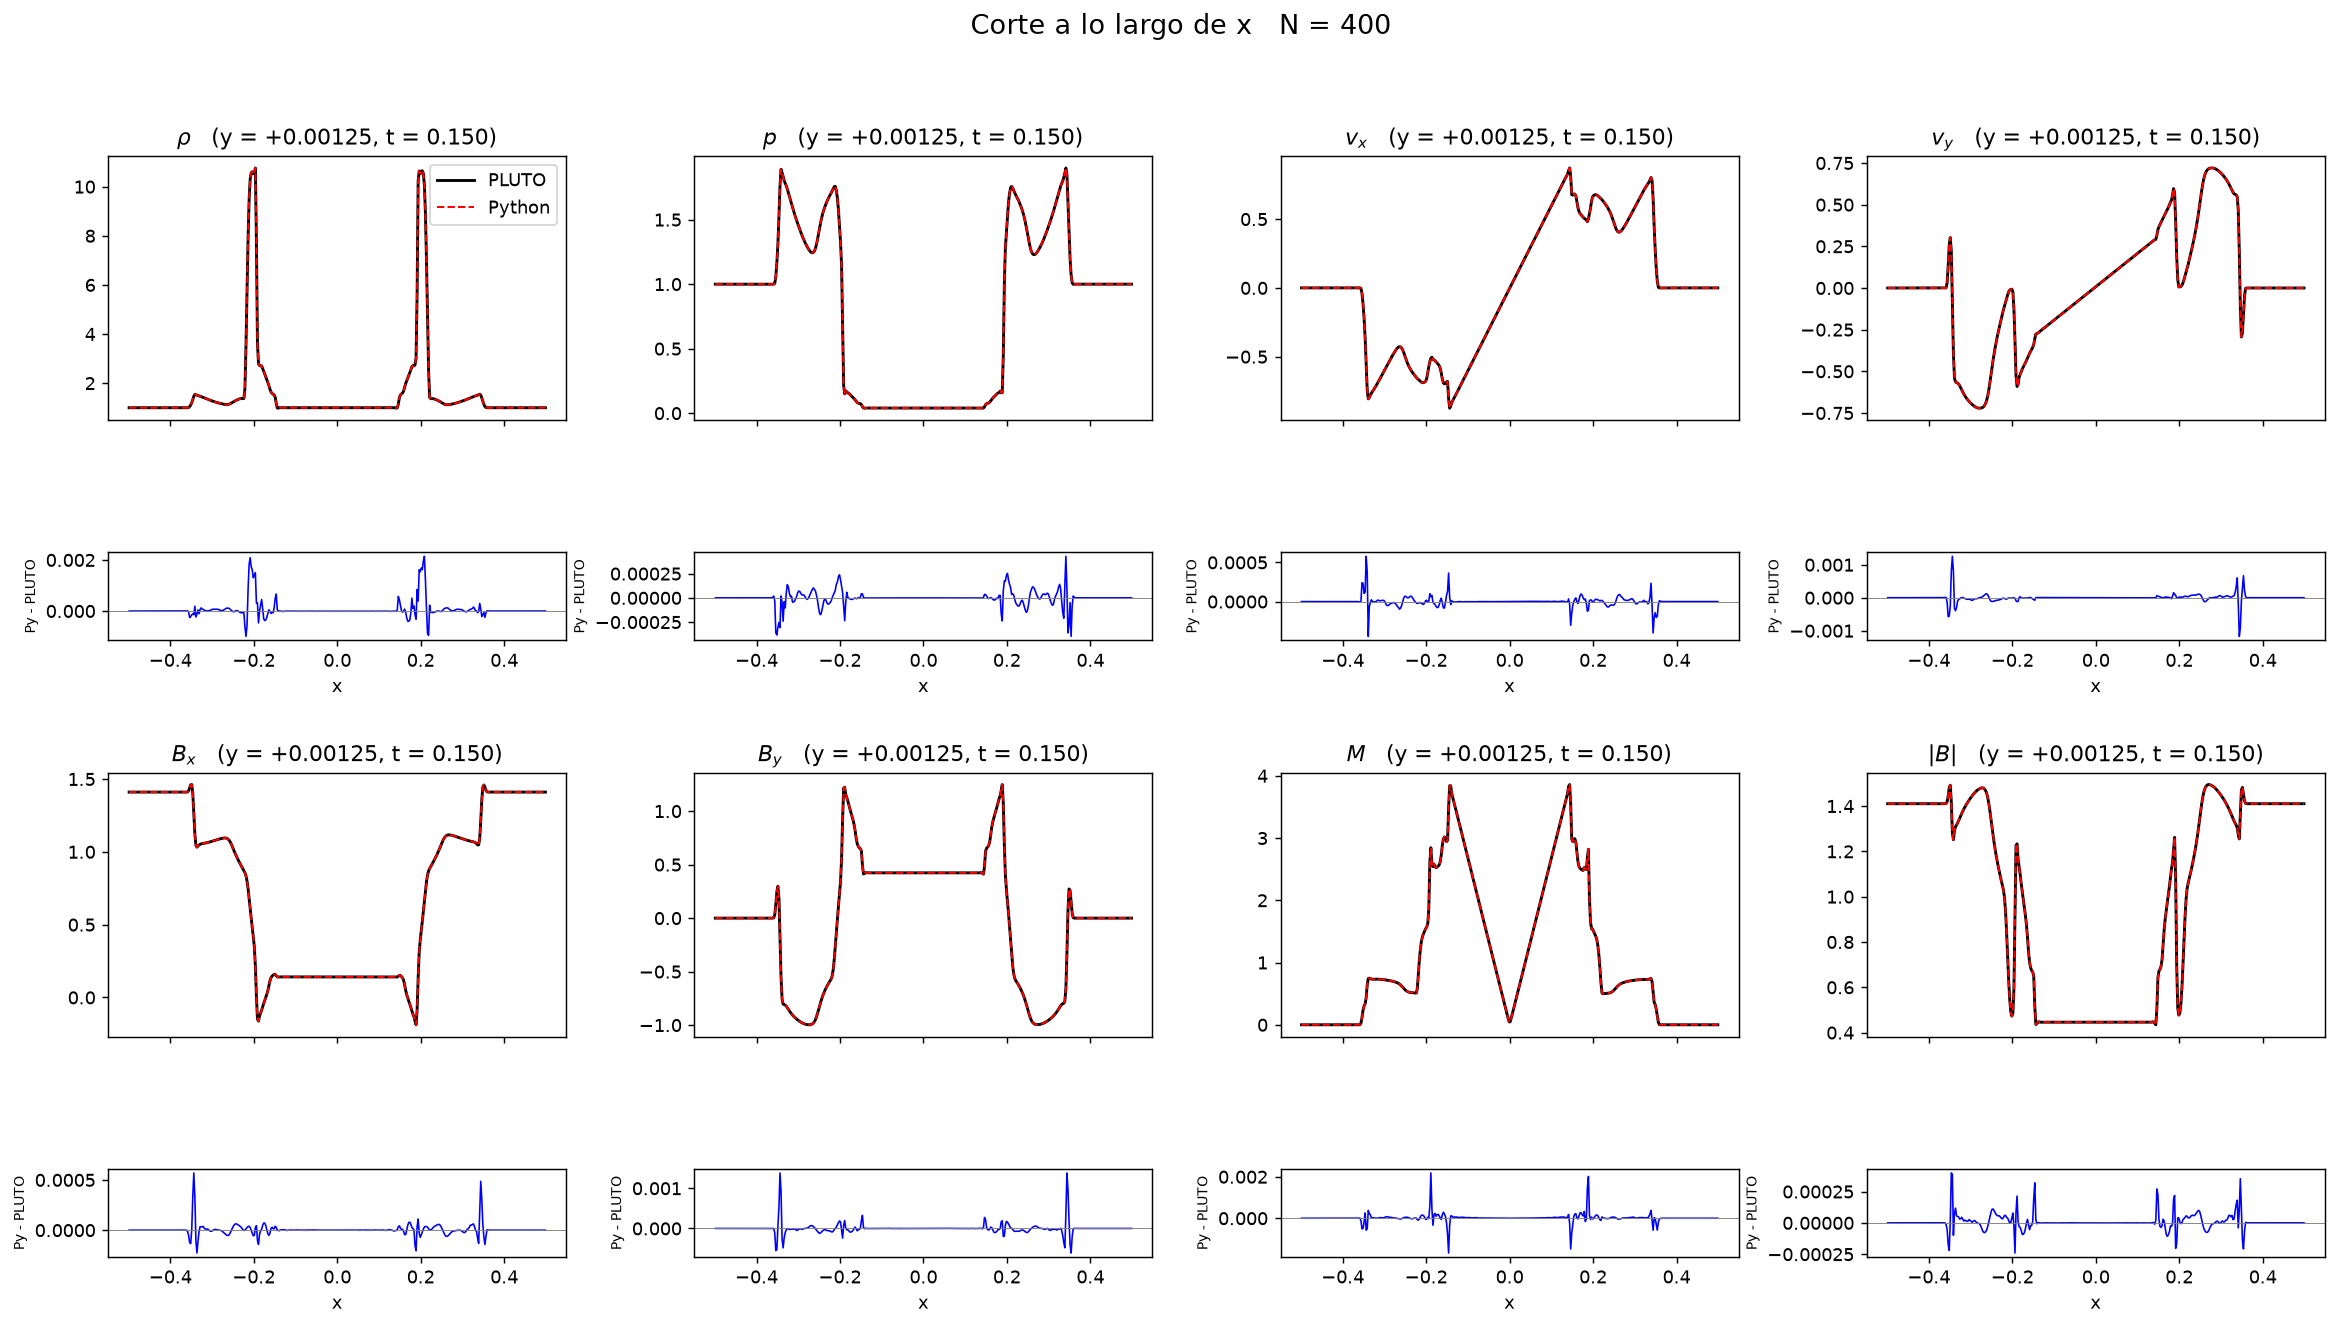

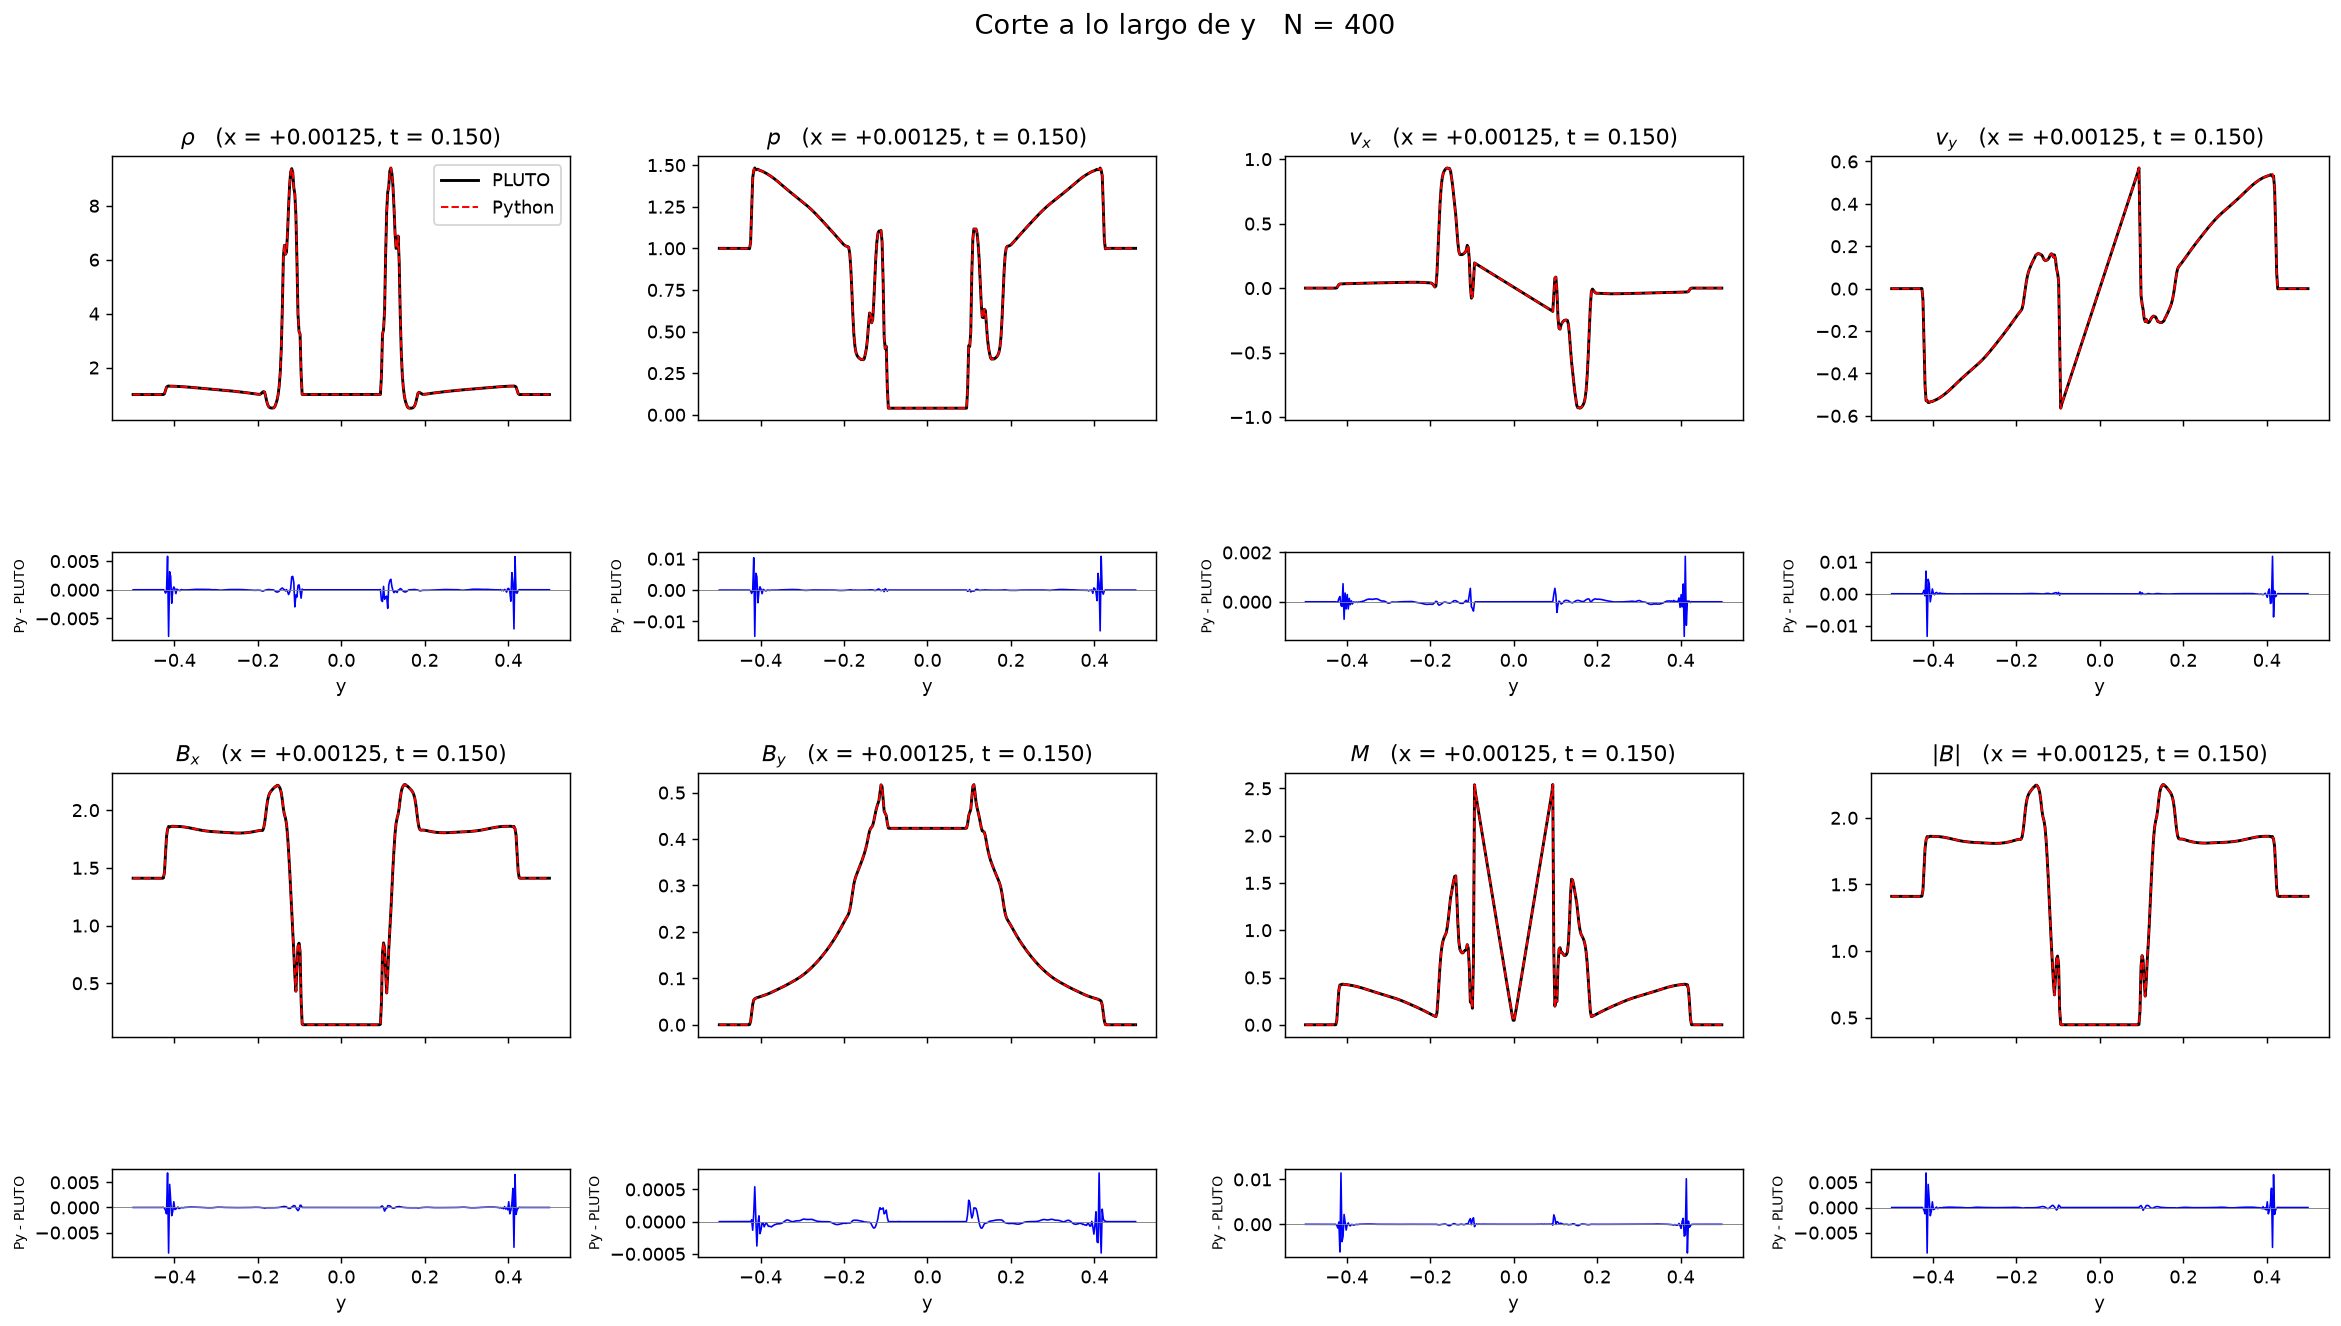

In [11]:
show(FIG / "compare_cut_y_0003.png", width=1200)
show(FIG / "compare_cut_x_0003.png", width=1200)

### 5.3 Mapas de diferencia

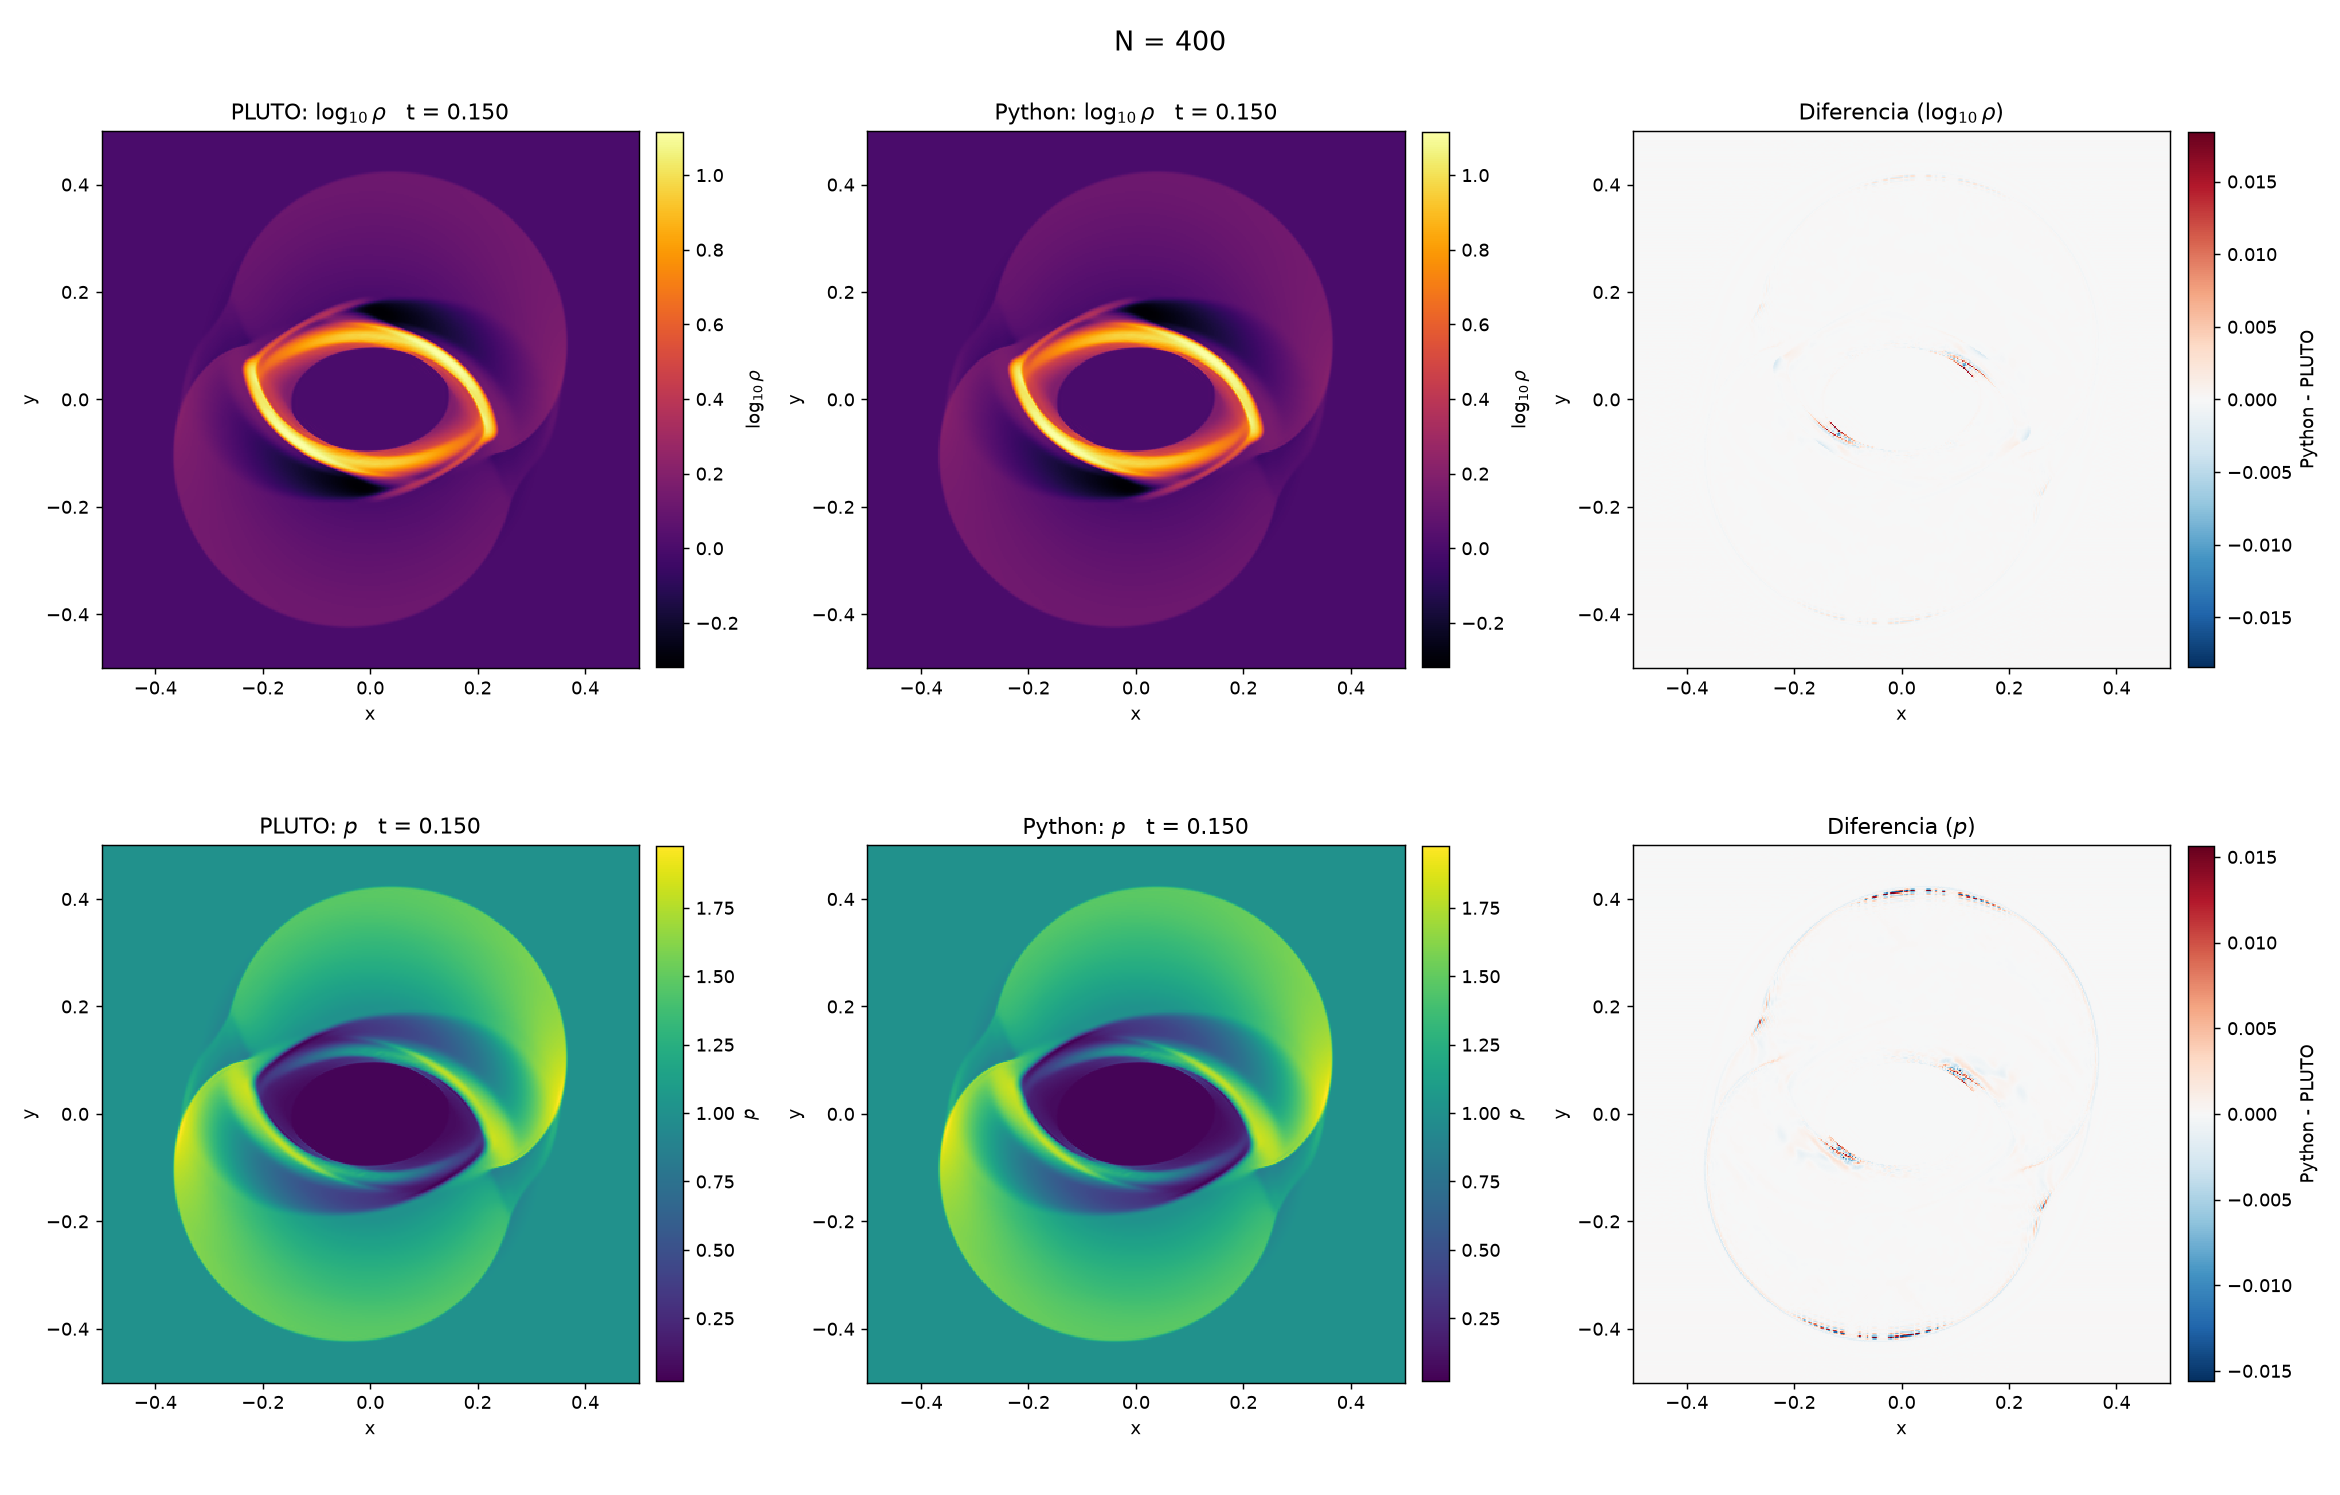

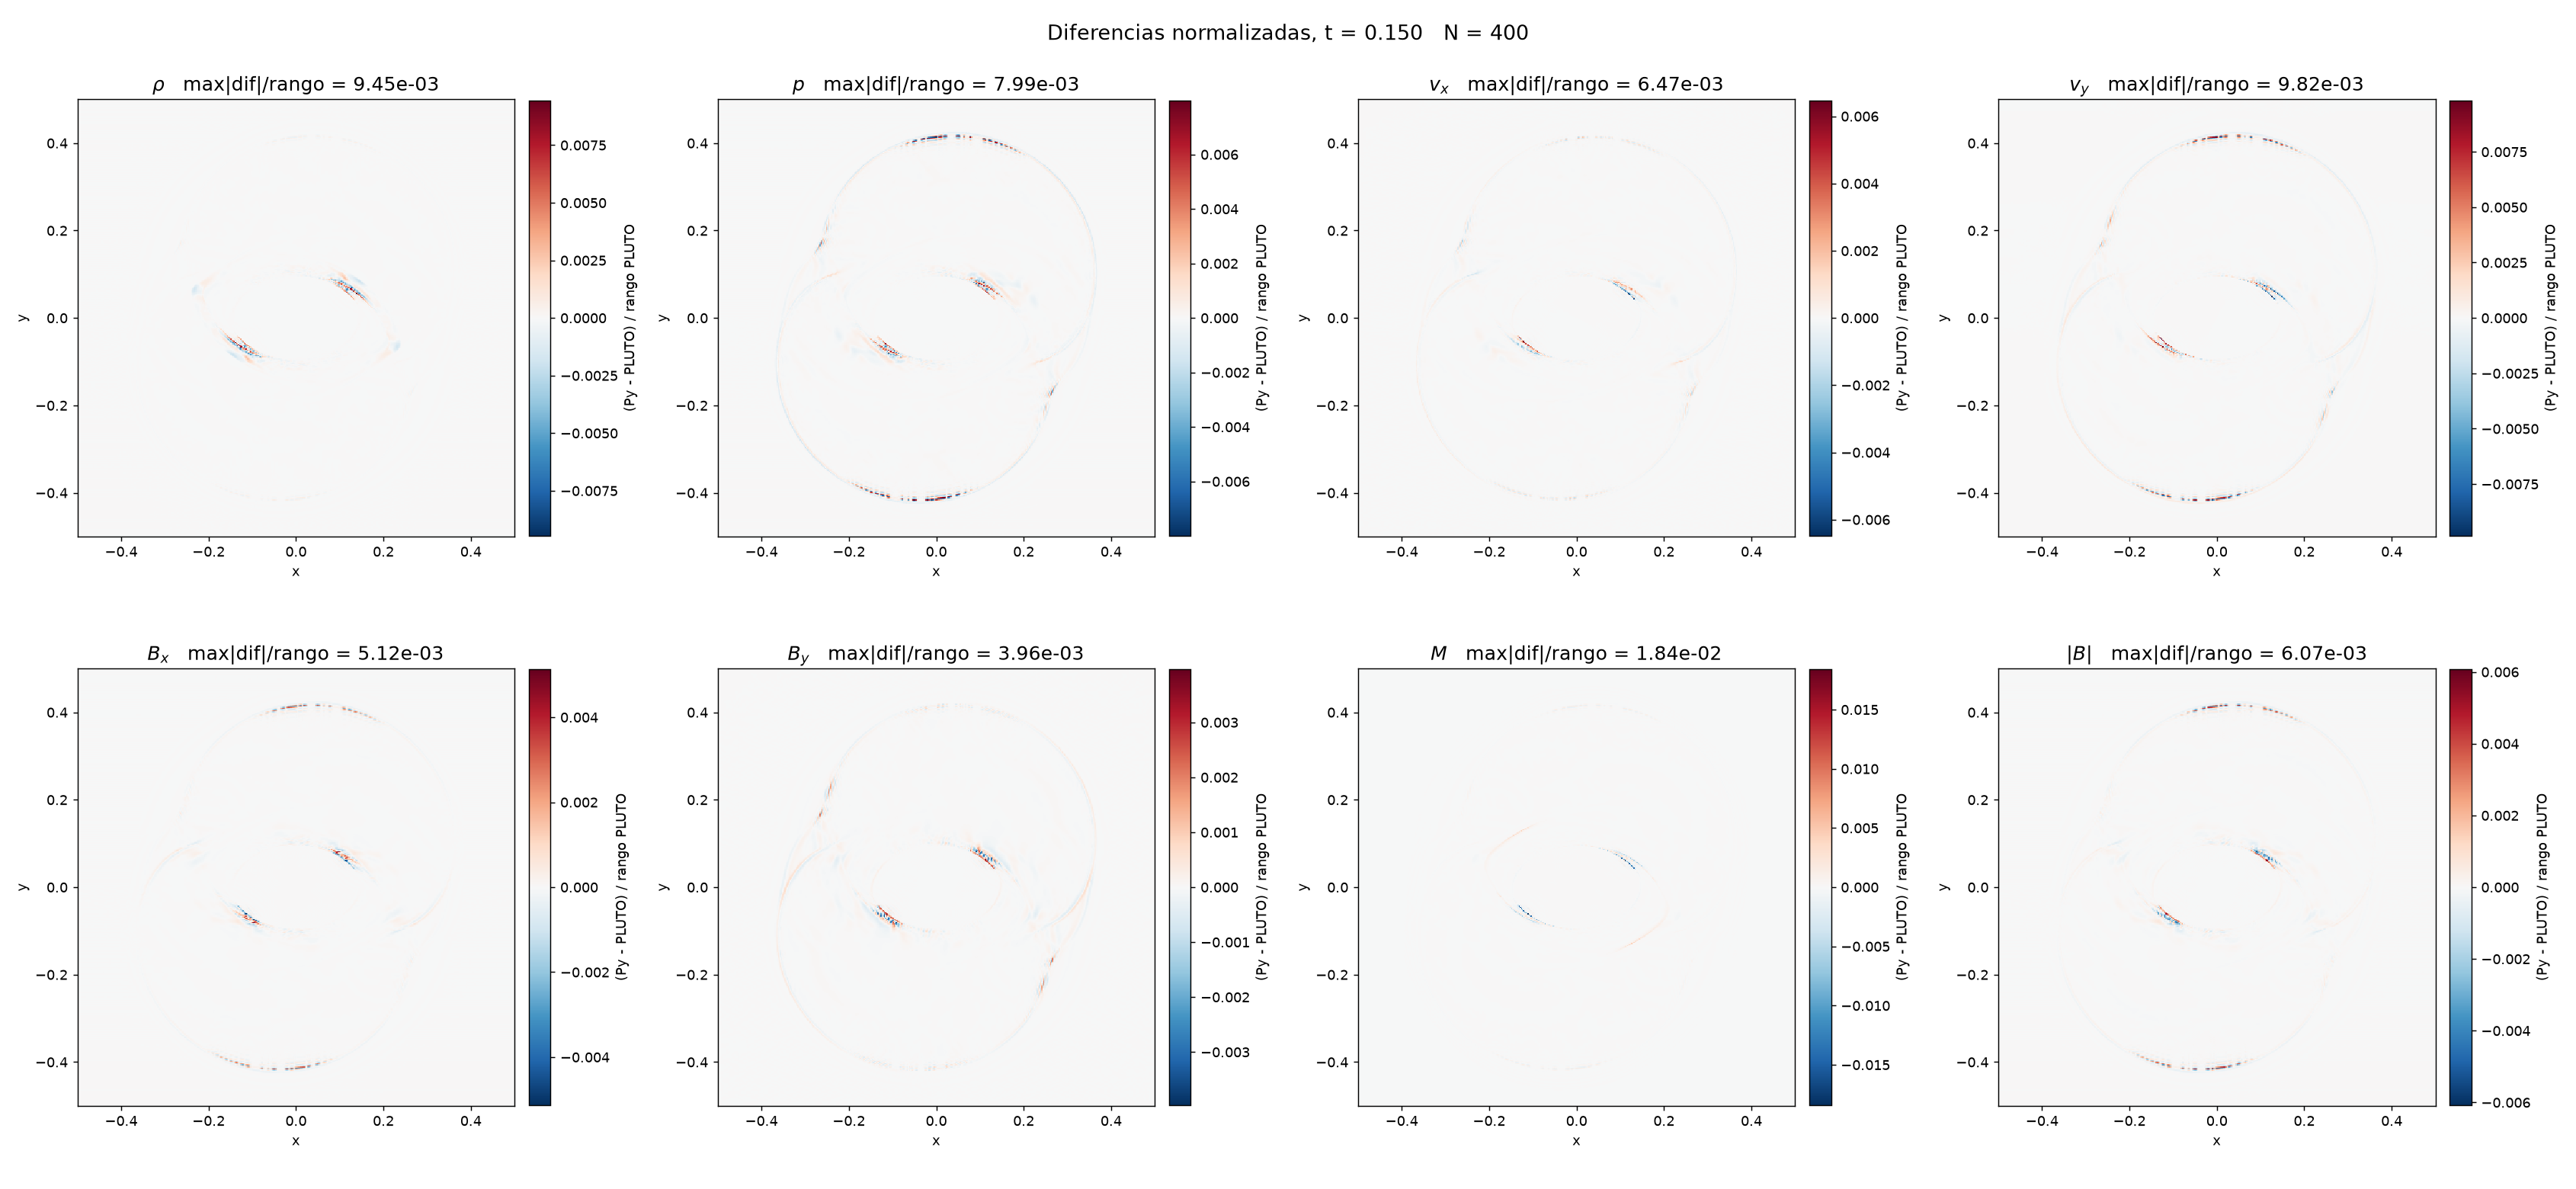

In [12]:
show(FIG / "compare_maps_rho_p_0003.png", width=1000)
show(FIG / "compare_diff_all_0003.png", width=1200)

### 5.4 Simetría y conservación

El solver preserva la simetría central del problema (rotación de 180°, $\rho,p,\mathbf B$ pares y $\mathbf v$ impar) a precisión de máquina; se calcula el error de asimetría de cada código y se compara con $\nabla\cdot\mathbf B$ y la masa.

In [13]:
fp = compare.load(PLUTO_DIR / "fields_0003.npz"); fy = compare.load(PY_DIR / "fields_0003.npz")
sp, sy = compare.symmetry_error(fp), compare.symmetry_error(fy)
dxdy = (fp["x"][1] - fp["x"][0]) * (fp["y"][1] - fp["y"][0])
out = ["| variable | asimetría PLUTO | asimetría Python |", "|---|---|---|"]
for k, _, _ in compare.VARS:
    out.append(f"| {names.get(k, k)} | {sp[k]:.1e} | {sy[k]:.1e} |")
display(Markdown("\n".join(out)))
print(f"masa    PLUTO {fp['rho'].sum()*dxdy:.8f}   Python {fy['rho'].sum()*dxdy:.8f}")
print(f"max|divB|  PLUTO {compare.divB(fp):.2e}   Python {compare.divB(fy):.2e}")

| variable | asimetría PLUTO | asimetría Python |
|---|---|---|
| ρ | 2.2e-15 | 3.9e-15 |
| p | 1.9e-14 | 2.7e-14 |
| v_x | 4.7e-15 | 1.3e-14 |
| v_y | 1.6e-14 | 2.8e-14 |
| B_x | 8.2e-15 | 8.8e-15 |
| B_y | 4.0e-15 | 1.3e-14 |
| Mach | 2.9e-15 | 5.3e-15 |
| \|B\| | 1.2e-14 | 1.3e-14 |

masa    PLUTO 1.32726536   Python 1.32726536
max|divB|  PLUTO 1.20e-11   Python 9.16e-12


### 5.5 Discusión de los errores (corrida $N=400$)

Con los resultados de `reporte/errores_N400.csv`:

- **El acuerdo es muy cercano.** En los tres instantes, $L_1\sim10^{-5}$–$4\times10^{-4}$ y $L_2\sim10^{-4}$–$2\times10^{-3}$ en todas las variables. Los extremos de los campos también coinciden: en $t=0.15$, $\rho\in[0.4810,\,13.0435]$ (Python) frente a $[0.4810,\,13.0479]$ (PLUTO) y $p_{\max}=1.975$ frente a $1.974$.
- **El error está en pocas celdas.** $P_{99}/\text{rango}<10^{-3}$ en todas las variables, mientras que $L_\infty/\text{rango}$ llega a $10^{-2}$ ($1.1\times10^{-2}$ en $\rho$ en $t=0.05$; $9.4\times10^{-3}$ en $\rho$ y $9.8\times10^{-3}$ en $v_y$ en $t=0.15$). El patrón es el de una discontinuidad desplazada una fracción de celda: el error se concentra en el anillo denso y los frentes.
- **Variables derivadas.** El Mach tiene el mayor $L_\infty$ ($1.8\times10^{-2}$ en $t=0.15$) porque es un cociente que amplifica el error donde $p$ y $\rho$ son pequeños (vacío central).
- **Evolución temporal.** El $L_1$ de $\rho$ crece de $8.7\times10^{-5}$ ($t=0.05$) a $2.0\times10^{-4}$ ($t=0.15$): crece lentamente, sin signos de inestabilidad ni de divergencia entre las soluciones.
- **Conservación.** $\nabla\cdot\mathbf B$ queda en el error de máquina ($10^{-12}$–$10^{-11}$) en ambos códigos y la masa coincide en las seis cifras impresas (ver celda 5.4).

**Posibles fuentes de la diferencia** (hipótesis, se contrastan en la sección 6):
1. *Paso de tiempo.* Python da 639 pasos y PLUTO 589; el error temporal de RK2 depende de $\Delta t$.
2. *Detalles del HLLD y la reconstrucción*: la estimación de $S_L$, $S_R$, los pisos de presión/densidad y el orden de las operaciones pueden diferir entre implementaciones.
3. *Redondeo y amplificación*: las diferencias de $10^{-16}$ se amplifican en choques; pero el error observado ($10^{-4}$) es muy superior, así que no basta para explicarlo.

## 6. Convergencia en malla y fuentes de error

Como el rotor tiene choques y no existe solución exacta, se usa **autoconvergencia**: la referencia es PLUTO a la mayor resolución disponible, promediada por bloques hasta cada malla $N$. En $t=0.15$ se miden

$$
e_{\rm PLUTO}(N)=\langle|q_{{\rm PLUTO},N}-q_{{\rm ref},N}|\rangle,\quad
e_{\rm Python}(N)=\langle|q_{{\rm Py},N}-q_{{\rm ref},N}|\rangle,\quad
d(N)=\langle|q_{{\rm Py},N}-q_{{\rm PLUTO},N}|\rangle .
$$

Cerca de choques y contactos se espera orden $p\approx1$ ($e\propto N^{-1}$) aunque el esquema sea de segundo orden en zonas suaves. Criterio de interpretación: si $d(N)$ decae al refinar con una pendiente similar a la de $e(N)$, los dos códigos difieren solo por **error de truncamiento**; si se **estanca**, existe una diferencia **sistemática** entre las dos implementaciones.

**Cómo generar las corridas** (desde `08_Proyecto2/`):

```bash
# --- PLUTO: la malla se lee de pluto.ini en tiempo de ejecución, no hay que recompilar ---
cd 08_Proyecto2/pluto
for N in 100 200 800; do
  cp pluto.ini pluto.ini.bak
  sed -i "s/^X1-grid.*/X1-grid    1    -0.5    $N    u    0.5/; s/^X2-grid.*/X2-grid    1    -0.5    $N    u    0.5/" pluto.ini
  ./pluto > run_$N.log 2>&1
  mkdir -p ../pluto_run_$N
  cp data.*.dbl dbl.out grid.out pluto.ini run_$N.log ../pluto_run_$N/
  mv pluto.ini.bak pluto.ini
done
cd ..
for N in 100 200 800; do python python/export_pluto.py pluto_run_$N; done

# --- Python (solo el instante final t = 0.15) ---
for N in 100 200 800; do python python/run_rotor.py -n $N --times 0 0.15; done
```

Tiempos aproximados (serie): PLUTO 800² ≈ 8 min; Python 800² ≈ 10 min con 2 núcleos (menos con más núcleos). Para 100² y 200² son segundos.

In [14]:
data = convergence.collect(Ns=(100, 200, 400, 800), root=ROOT)
print("Corridas disponibles (código, N):", sorted(data))
rows_c, Nref = convergence.analyze(data)
if not rows_c:
    print("\nFaltan corridas: se necesitan al menos 2 resoluciones de PLUTO (la mayor es la referencia).")
else:
    convergence.save_csv(rows_c, REP / "convergencia.csv")
    fig = convergence.plot(rows_c, Nref, FIG / "convergencia.png")
    plt.show()
    out = [f"Referencia: PLUTO {Nref}². Orden observado $p$ (pendiente de $e\\propto N^{{-p}}$):", "",
           "| variable | $p$ PLUTO | $p$ Python | $p$ de $d(N)$ |", "|---|---|---|---|"]
    for k, lab in convergence.VARS:
        o = [convergence.observed_order(rows_c, k, c) for c in ("e_pluto", "e_python", "d_py_pl")]
        out.append(f"| {names.get(k, k)} | " + " | ".join("—" if np.isnan(v) else f"{v:.2f}" for v in o) + " |")
    display(Markdown("\n".join(out)))

Corridas disponibles (código, N): [('pluto', 400), ('python', 400)]

Faltan corridas: se necesitan al menos 2 resoluciones de PLUTO (la mayor es la referencia).


### Interpretación de la convergencia

_(Completar con los resultados de la celda anterior: orden observado en PLUTO y Python, y si $d(N)$ decae o se estanca.)_

### Experimento opcional: sensibilidad al paso de tiempo

Con `SUM_DIRECTIONS = True` en `mhd_core.py` el solver usa $\Delta t\propto1/\max_{ij}\sum_d\lambda_d/\Delta_d$ (≈1100 pasos en lugar de 639). Comparar la diferencia con PLUTO en ambos casos cuantifica cuánto pesa el paso de tiempo en la discrepancia de la sección 5.

## 7. Conclusiones

1. **Se reprodujo el MHD Rotor (config. #01) con PLUTO y con un solver propio** (HLLD + MC + CT + RK2) en $400\times400$. Ambas soluciones muestran la misma morfología: rotor deformado en elipse, vacío central de presión, anillo denso, frentes rápidos de dos lóbulos y torsión de las líneas de campo; $M_{\max}\approx7$.
2. **El solver propio se verificó de forma independiente**: HLLD consistente a $10^{-16}$, onda de Alfvén con convergencia de orden $\approx1.9$ y simetría entre direcciones $x$/$y$ a $10^{-14}$.
3. **La comparación es muy cercana**: $L_1\lesssim4\times10^{-4}$ y $P_{99}/\text{rango}<10^{-3}$ en todas las variables y snapshots, con $L_\infty/\text{rango}\lesssim2\times10^{-2}$ concentrado en pocas celdas de choque. Los extremos de $\rho$ y $p$ coinciden a $\lesssim1\%$ (en $t=0.15$: $\rho_{\max}$ a $0.03\%$, $p_{\max}$ a $0.04\%$).
4. **El CT mantiene $\nabla\cdot\mathbf B$ en el error de máquina ($10^{-12}$–$10^{-11}$)** en ambos códigos, lo que valida la implementación escalonada con EMF aritmético, y la simetría central de la solución se conserva a precisión de máquina.
5. **Origen de la discrepancia residual:** _(completar tras la sección 6: truncamiento frente a diferencia sistemática; efecto del paso de tiempo)_.

**Trabajo futuro.** Resoluciones mayores, comparar con otras configuraciones de PLUTO (GLM, 8 ondas, geometría polar), y un esquema de orden superior (WENO + CT) para reducir el error en los choques [16].

## 8. Referencias

[1] D. S. Balsara & D. S. Spicer, *A staggered mesh algorithm using high order Godunov fluxes to ensure solenoidal magnetic fields in magnetohydrodynamic simulations*, J. Comput. Phys. **149**, 270 (1999).
[2] G. Tóth, *The ∇·B=0 constraint in shock-capturing magnetohydrodynamics codes*, J. Comput. Phys. **161**, 605 (2000).
[3] D. S. Balsara & J. Kim, *An intercomparison between divergence-cleaning and staggered mesh formulations for numerical magnetohydrodynamics*, Astrophys. J. **602**, 1079 (2004); arXiv:astro-ph/0310728.
[4] C. R. Evans & J. F. Hawley, *Simulation of magnetohydrodynamic flows: a constrained transport method*, Astrophys. J. **332**, 659 (1988).
[5] T. A. Gardiner & J. M. Stone, *An unsplit Godunov method for ideal MHD via constrained transport*, J. Comput. Phys. **205**, 509 (2005).
[6] P. Londrillo & L. Del Zanna, *On the divergence-free condition in Godunov-type schemes for ideal magnetohydrodynamics: the upwind constrained transport method*, J. Comput. Phys. **195**, 17 (2004).
[7] T. Miyoshi & K. Kusano, *A multi-state HLL approximate Riemann solver for ideal magnetohydrodynamics*, J. Comput. Phys. **208**, 315 (2005).
[8] A. Dedner, F. Kemm, D. Kröner, C.-D. Munz, T. Schnitzer & M. Wesenberg, *Hyperbolic divergence cleaning for the MHD equations*, J. Comput. Phys. **175**, 645 (2002).
[9] K. G. Powell, P. L. Roe, T. J. Linde, T. I. Gombosi & D. L. De Zeeuw, *A solution-adaptive upwind scheme for ideal magnetohydrodynamics*, J. Comput. Phys. **154**, 284 (1999).
[10] D. Derigs, A. R. Winters, G. J. Gassner, S. Walch & M. Bohm, *Ideal GLM-MHD: about the entropy consistent nine-wave magnetic field divergence diminishing ideal magnetohydrodynamics equations*, J. Comput. Phys. (2018), doi:10.1016/j.jcp.2018.03.002; arXiv:1711.06269.
[11] J. M. Stone et al., *The Athena++ adaptive mesh refinement framework: design and magnetohydrodynamic solvers*, Astrophys. J. Suppl. **249**, 4 (2020); arXiv:2005.06651.
[12] G. R. J. Lesur, S. Baghdadi, G. Wafflard-Fernandez, J. Mauxion, C. M. T. Robert & M. Van den Bossche, *IDEFIX: a versatile performance-portable Godunov code for astrophysical flows*, Astron. Astrophys. (2023), doi:10.1051/0004-6361/202346005; arXiv:2304.13746.
[13] M. Rossazza, A. Mignone, M. Bugli, S. Truzzi, L. Riha, T. Panoc, O. Vysocky, N. Shukla, A. Romeo & V. Berta, *The PLUTO code on GPUs: a first look at Eulerian MHD methods*, arXiv:2511.20337 (2025).
[14] A. Mignone, G. Bodo, S. Massaglia, T. Matsakos, O. Tesileanu, C. Zanni & A. Ferrari, *PLUTO: a numerical code for computational astrophysics*, Astrophys. J. Suppl. **170**, 228 (2007) (ver §5.4); y documentación del problema `Test_Problems/MHD/Rotor` (A. Mignone).
[15] A. Mignone, C. Zanni, P. Tzeferacos et al., *The PLUTO code for adaptive mesh computations in astrophysical fluid dynamics*, Astrophys. J. Suppl. **198**, 7 (2012).
[16] J. Seo & D. Ryu, *HOW-MHD: a high-order WENO-based magnetohydrodynamic code with a high-order constrained transport algorithm for astrophysical applications*, arXiv:2304.04360.
[17] W. Zeng & Q. Wang, *A locally divergence-free oscillation-eliminating discontinuous Galerkin method for ideal magnetohydrodynamic equations*, arXiv:2404.14274 (2024).

*Nota:* se recomienda verificar volumen y páginas de las referencias clásicas antes de la entrega final.

### Reproducibilidad

```bash
cd 08_Proyecto2/python
python tests_solver.py                                  # verificación del solver
python run_rotor.py -n 400                              # solver Python (usa ../pluto_run_400/dbl.out para los tiempos)
python export_pluto.py ../pluto_run_400                 # dbl de PLUTO -> fields_000k.npz
python plot_python.py   &&   python compare.py          # figuras y tabla de errores
```
Dependencias: `numpy`, `scipy`, `matplotlib`, `numba`, `pyPLUTO` 1.2.6 (solo para las figuras de PLUTO). Código en `python/`, entradas de PLUTO en `pluto/`.